# Solving Durable model with search in infinite horizon

Compare steady-state aggregates and sequence-space Jacobians w.r.t. `Rfree` and `labor` across
search-cost magnitudes matching `Figures_Durable.ipynb` panel (b):

- $S \in \{0.3\}$ *Large shock*
- Taste and price shut off (`sigma_eps=0`, `PriceShkStd=0`)

Saves results to `Output/DurableModel_Search_Inf_SS.pkl`,
`Output/DurableModel_Search_Inf_Jacobians_Rfree.pkl`, and
`Output/DurableModel_Search_Inf_Jacobians_labor.pkl`.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import copy
import time
import datetime
import pickle
from pathlib import Path

import pandas as pd
from IPython.display import display

start_time = time.time()

from DurableModel_Fast import DurableConsumer

FIG_DIR = Path("../Figures/DurableModel")
FIG_DIR.mkdir(parents=True, exist_ok=True)

OUT_DIR = Path("../Output")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Line styles matching Figures_Durable.ipynb smoothing-shift overlays
LINE_STYLES = [
    ("k", "-"),
    ("r", "-"),
    ("k", "--"),
    ("k", ":"),
]

# Styles for n-example curves on combined policy plots (Figures_Durable)
N_LINE_STYLES = [
    ("k", "-"),
    ("r", "-"),
    ("k", "--"),
    ("k", ":"),
]
N_SHOW_DEFAULT = (0.5, 1.0, 1.5, 2.0)

SS_KEYS = ["C", "D", "DEX", "TEX", "A", "ADJ"]
JAC_KEYS = ["C", "DEX", "TEX", "D", "A", "ADJ"]


def plot_combined_policies(
    models,
    labels,
    title,
    fname_prefix,
    t=-1,
    n_vals=N_SHOW_DEFAULT,
    m_max=None,
):
    """Combined (total) c(n,m) and d(n,m) policy plots at period t."""
    n_vals = tuple(n_vals)
    title_T = title + r", $t = T$" if t == -1 else title + rf", $t = {t}$"

    def _m_grid(model):
        m = np.asarray(model.solution[t].mNrmGrid, dtype=float)
        if m_max is not None:
            m = m[m <= m_max]
        return m

    def _draw(ax, sol, m, which):
        for n0, (color, ls) in zip(n_vals, N_LINE_STYLES):
            n_vec = np.full_like(m, float(n0), dtype=float)
            y = sol.cFunc(n_vec, m) if which == "c" else sol.dFunc(n_vec, m)
            ax.plot(m, y, color=color, linestyle=ls, label=rf"$n={n0:g}$")
        ax.set_xlabel(r"Market resources, $m_t$")
        ax.grid(color="k", linestyle=":", linewidth=0.5)
        ax.legend(loc=4)

    if len(models) == 1:
        fig, ax = plt.subplots(figsize=(6.5, 4.5))
        sol = models[0].solution[t]
        _draw(ax, sol, _m_grid(models[0]), "c")
        ax.set_ylabel(r"Non-durable consumption, $c(n_t,m_t)$")
        ax.set_title(title_T)
        fig.tight_layout()
    else:
        fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)
        axes = axes.ravel()
        for ax, model, lab in zip(axes, models, labels):
            _draw(ax, model.solution[t], _m_grid(model), "c")
            ax.set_title(lab)
            ax.set_ylabel(r"$c(n_t,m_t)$")
        for ax in axes[len(models) :]:
            ax.set_visible(False)
        fig.suptitle(title_T, y=0.98)
        fig.tight_layout(rect=[0.0, 0.0, 1.0, 0.96])
    fig.savefig(FIG_DIR / f"{fname_prefix}_c_T.pdf", dpi=150)
    plt.show()

    if len(models) == 1:
        fig, ax = plt.subplots(figsize=(6.5, 4.5))
        sol = models[0].solution[t]
        _draw(ax, sol, _m_grid(models[0]), "d")
        ax.set_ylabel(r"Durable consumption, $d(n_t,m_t)$")
        ax.set_title(title_T)
        fig.tight_layout()
    else:
        fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)
        axes = axes.ravel()
        for ax, model, lab in zip(axes, models, labels):
            _draw(ax, model.solution[t], _m_grid(model), "d")
            ax.set_title(lab)
            ax.set_ylabel(r"$d(n_t,m_t)$")
        for ax in axes[len(models) :]:
            ax.set_visible(False)
        fig.suptitle(title_T, y=0.98)
        fig.tight_layout(rect=[0.0, 0.0, 1.0, 0.96])
    fig.savefig(FIG_DIR / f"{fname_prefix}_d_T.pdf", dpi=150)
    plt.show()


def _heatmap_grid(models, panel_titles, t, fname, Z_list, cbar_label, vmin, vmax, cmap, suptitle=None):
    """Shared pcolormesh layout for Ss panels."""
    n = len(models)
    if n == 1:
        fig, axes = plt.subplots(1, 1, figsize=(6.0, 4.5))
        axes = np.array([axes])
    else:
        fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)
        axes = axes.ravel()

    last_pcm = None
    for ax, model, ptitle, Z in zip(axes, models, panel_titles, Z_list):
        sol = model.solution[t]
        last_pcm = ax.pcolormesh(
            sol.mNrmGrid,
            sol.nNrmGrid,
            Z,
            cmap=cmap,
            shading="auto",
            vmin=vmin,
            vmax=vmax,
        )
        ax.set_title(ptitle)
        ax.set_xlabel(r"Market resources, $m_t$")
        ax.set_ylabel(r"Durable stock, $n_t$")

    for ax in axes[n:]:
        ax.set_visible(False)

    if suptitle:
        fig.suptitle(suptitle, y=0.98)
    fig.tight_layout(rect=[0.0, 0.14, 1.0, 0.96 if suptitle else 1.0])
    cbar_ax = fig.add_axes([0.2, 0.04, 0.6, 0.03])
    fig.colorbar(last_pcm, cax=cbar_ax, orientation="horizontal", label=cbar_label)
    fig.savefig(FIG_DIR / fname, dpi=150, bbox_inches="tight")
    plt.show()


def plot_ss_heatmaps(models, panel_titles, t, fname, suptitle=None):
    """S,s / adjusting heatmaps; viridis as in Figures_Durable."""
    Z_list = [model.solution[t].adjusting_arr for model in models]
    _heatmap_grid(
        models,
        panel_titles,
        t,
        fname,
        Z_list,
        cbar_label=r"adjusting / $\mathbb{E}[\varepsilon^*]$ / $P^{\mathrm{adj}}$",
        vmin=0.0,
        vmax=1.0,
        cmap="viridis",
        suptitle=suptitle,
    )


def plot_case_heatmaps(models, panel_titles, t, fname_stem, suptitle=None):
    """Ss at period t and terminal."""
    plot_ss_heatmaps(models, panel_titles, t, f"{fname_stem}_Ss.pdf", suptitle=suptitle)
    plot_ss_heatmaps(
        models, panel_titles, -1, f"{fname_stem}_Ss_T.pdf",
        suptitle=(suptitle + r" (terminal)") if suptitle else r"Terminal period",
    )


def plot_ergodic_heatmaps(models, panel_titles, fname, suptitle=None, log=True):
    """
    Ergodic distribution heatmaps on (dist_nGrid, dist_mGrid).

    Same panel layout as the Ss adjusting heatmaps. Uses log10 mass by default
    because stationary probability is typically highly concentrated.
    Requires ``compute_steady_state()`` (sets ``erg_dstn``).
    """
    from matplotlib.colors import LogNorm

    n = len(models)
    if n == 1:
        fig, axes = plt.subplots(1, 1, figsize=(6.0, 4.5))
        axes = np.array([axes])
    else:
        fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)
        axes = axes.ravel()

    last_pcm = None
    cbar_label = (
        r"stationary mass (log$_{10}$)" if log else r"stationary mass"
    )
    for ax, model, ptitle in zip(axes, models, panel_titles):
        Z = np.asarray(model.erg_dstn, dtype=float)
        Z = np.maximum(Z, 0.0)
        if log:
            z_pos = Z[Z > 0.0]
            if z_pos.size == 0:
                raise ValueError("erg_dstn has no positive mass to plot on a log scale")
            norm = LogNorm(vmin=z_pos.min(), vmax=Z.max())
            last_pcm = ax.pcolormesh(
                model.dist_mGrid,
                model.dist_nGrid,
                Z,
                cmap="magma",
                shading="auto",
                norm=norm,
            )
        else:
            last_pcm = ax.pcolormesh(
                model.dist_mGrid,
                model.dist_nGrid,
                Z,
                cmap="magma",
                shading="auto",
                vmin=0.0,
            )
        ax.set_title(ptitle)
        ax.set_xlabel(r"Market resources, $m$")
        ax.set_ylabel(r"Durable stock, $n$")

    for ax in axes[n:]:
        ax.set_visible(False)

    if suptitle:
        fig.suptitle(suptitle, y=0.98)
    fig.tight_layout(rect=[0.0, 0.14, 1.0, 0.96 if suptitle else 1.0])
    cbar_ax = fig.add_axes([0.2, 0.04, 0.6, 0.03])
    fig.colorbar(last_pcm, cax=cbar_ax, orientation="horizontal", label=cbar_label)
    fig.savefig(FIG_DIR / fname, dpi=150, bbox_inches="tight")
    plt.show()


def plot_ergodic_ss_overlay(
    models,
    panel_titles,
    fname,
    suptitle=None,
    log=True,
    border=(1e-3, 1.0 - 1e-3),
    levels=None,
):
    """
    Ergodic mass with adjusting contours on the dist grid, plus a mass-weighted
    histogram of P(adj).

    Draws the ≈0 and ≈1 frontiers of ``P^{adj}`` (``border``) so the continuous
    mixing band ``border[0] < P < border[1]`` is visible, lightly shaded.
    Steady-state ``ADJ`` is ``E_μ[P(adj)]``, not mass where ``P≈1``.

    Uses ``erg_dstn`` and ``adj_ss`` from ``compute_steady_state``.
    """
    from matplotlib.colors import LogNorm

    p0, p1 = float(border[0]), float(border[1])

    n = len(models)
    if n == 1:
        fig, axes = plt.subplots(1, 1, figsize=(6.5, 5.0))
        axes = np.array([axes])
    else:
        fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)
        axes = axes.ravel()

    last_pcm = None
    cbar_label = (
        r"stationary mass (log$_{10}$)" if log else r"stationary mass"
    )
    for ax, model, ptitle in zip(axes, models, panel_titles):
        Z = np.maximum(np.asarray(model.erg_dstn, dtype=float), 0.0)
        adj = np.asarray(model.adj_ss, dtype=float)
        m_grid = np.asarray(model.dist_mGrid, dtype=float)
        n_grid = np.asarray(model.dist_nGrid, dtype=float)
        M, N = np.meshgrid(m_grid, n_grid)

        E_P = float((Z * adj).sum())
        adj_ss_ref = float(getattr(model, "ADJ_ss", E_P))
        amin, amax = float(np.nanmin(adj)), float(np.nanmax(adj))

        if log:
            z_pos = Z[Z > 0.0]
            if z_pos.size == 0:
                raise ValueError("erg_dstn has no positive mass to plot on a log scale")
            norm = LogNorm(vmin=z_pos.min(), vmax=Z.max())
            last_pcm = ax.pcolormesh(
                m_grid, n_grid, Z, cmap="magma", shading="auto", norm=norm,
            )
        else:
            last_pcm = ax.pcolormesh(
                m_grid, n_grid, Z, cmap="magma", shading="auto", vmin=0.0,
            )

        # Shade continuous mixing band p0 < P < p1 (clipped to data range).
        band_lo = max(p0, amin + 1e-12)
        band_hi = min(p1, amax - 1e-12)
        if band_hi > band_lo:
            ax.contourf(
                M, N, adj,
                levels=[band_lo, band_hi],
                colors=[(0.3, 0.85, 1.0)],
                alpha=0.28,
            )

        # Main frontiers: where P leaves ≈0 and where it reaches ≈1.
        frontier_lvl = []
        frontier_colors = []
        frontier_widths = []
        frontier_labels = {}
        if amin < p0 < amax:
            frontier_lvl.append(p0)
            frontier_colors.append("white")
            frontier_widths.append(2.0)
            frontier_labels[p0] = r"$P\!\approx\!0$"
        if amin < p1 < amax:
            frontier_lvl.append(p1)
            frontier_colors.append("yellow")
            frontier_widths.append(2.0)
            frontier_labels[p1] = r"$P\!\approx\!1$"

        # Optional extras (E[P], custom levels); keep thinner.
        extra = []
        if levels is not None:
            extra.extend(float(L) for L in levels)
        if 0.0 < E_P < 1.0:
            extra.append(E_P)
        extra_lvl, extra_colors, extra_widths = [], [], []
        for L in sorted(set(extra)):
            if L in frontier_lvl:
                continue
            if not (amin < L < amax):
                continue
            extra_lvl.append(L)
            if abs(L - E_P) < 1e-6:
                extra_colors.append("lime")
                extra_widths.append(1.6)
            else:
                extra_colors.append("cyan")
                extra_widths.append(1.0)

        if frontier_lvl:
            cs0 = ax.contour(
                M, N, adj, levels=frontier_lvl,
                colors=frontier_colors, linewidths=frontier_widths,
            )
            ax.clabel(
                cs0,
                fmt=lambda v, _m=frontier_labels: _m.get(
                    float(np.round(v, 12)), rf"$P={v:g}$"
                ),
                fontsize=8,
            )
        if extra_lvl:
            cs1 = ax.contour(
                M, N, adj, levels=extra_lvl,
                colors=extra_colors, linewidths=extra_widths,
            )
            ax.clabel(
                cs1,
                fmt=lambda v: (
                    rf"$\mathbb{{E}}[P]={v:.3f}$" if abs(v - E_P) < 1e-6
                    else rf"$P={v:g}$"
                ),
                fontsize=7,
            )

        mass = Z.ravel()
        a = adj.ravel()
        m_keep = float(mass[a <= p0].sum())
        m_band = float(mass[(a > p0) & (a < p1)].sum())
        m_adj = float(mass[a >= p1].sum())
        flow = a * mass
        flow_tot = float(flow.sum()) + 1e-16
        flow_in_band = float(flow[(a > p0) & (a < p1)].sum()) / flow_tot

        ax.set_title(
            ptitle
            + "\n"
            + rf"$\mathbb{{E}}_\mu[P]^{{\mathrm{{adj}}}}={E_P:.4f}$"
            + rf" (ADJ$={adj_ss_ref:.4f}$)"
            + "\n"
            + rf"mass: $P\leq{p0:g}$: {m_keep:.3f}, "
            + rf"continuous: {m_band:.3f}, "
            + rf"$P\geq{p1:g}$: {m_adj:.3f}"
        )
        ax.set_xlabel(r"Market resources, $m$")
        ax.set_ylabel(r"Durable stock, $n$")
        print(
            f"{ptitle}: E_mu[P(adj)]={E_P:.6f} (ADJ_ss={adj_ss_ref:.6f}); "
            f"P(adj) in [{amin:.4g}, {amax:.4g}]; "
            f"mass P<={p0:g}: {m_keep:.4f}, continuous ({p0:g}<P<{p1:g}): {m_band:.4f}, "
            f"P>={p1:g}: {m_adj:.4f}; "
            f"share of ADJ flow from continuous band: {flow_in_band:.3f}"
        )
        if p1 >= amax:
            print(
                f"  note: max P(adj)={amax:.4g} < border high={p1:g} "
                f"— no P≈1 contour on this grid"
            )
        if p0 <= amin:
            print(
                f"  note: min P(adj)={amin:.4g} > border low={p0:g} "
                f"— no P≈0 contour on this grid"
            )

    for ax in axes[n:]:
        ax.set_visible(False)

    if suptitle:
        fig.suptitle(
            (suptitle + "\n" if suptitle else "")
            + r"white: $P\!\approx\!0$, yellow: $P\!\approx\!1$, "
            + r"cyan band: continuous $(0,1)$; "
            + r"ADJ $=\mathbb{E}_\mu[P^{\mathrm{adj}}]$",
            y=1.02,
        )
    fig.tight_layout(rect=[0.0, 0.14, 1.0, 0.90])
    cbar_ax = fig.add_axes([0.2, 0.04, 0.6, 0.03])
    fig.colorbar(last_pcm, cax=cbar_ax, orientation="horizontal", label=cbar_label)
    fig.savefig(FIG_DIR / fname, dpi=150, bbox_inches="tight")
    plt.show()

    fig_h, axes_h = plt.subplots(
        1, n, figsize=(4.5 * n, 3.6), sharey=True, squeeze=False,
    )
    for ax, model, ptitle in zip(axes_h[0], models, panel_titles):
        Z = np.maximum(np.asarray(model.erg_dstn, dtype=float), 0.0).ravel()
        a = np.asarray(model.adj_ss, dtype=float).ravel()
        E_P = float((Z * a).sum())
        bins = np.linspace(0.0, 1.0, 41)
        ax.hist(a, bins=bins, weights=Z, color="0.35", edgecolor="w", linewidth=0.4)
        ax.axvline(E_P, color="lime", lw=2.0, label=rf"$\mathbb{{E}}[P]={E_P:.3f}$")
        ax.axvline(p0, color="w", lw=1.4, label=rf"$P\!\approx\!0$ ({p0:g})")
        ax.axvline(p1, color="gold", lw=1.4, label=rf"$P\!\approx\!1$ ({p1:g})")
        ax.set_xlabel(r"$P^{\mathrm{adj}}(n,m)$")
        ax.set_ylabel(r"Ergodic mass")
        ax.set_title(ptitle)
        ax.legend(loc=1, fontsize=7)
        ax.grid(color="k", linestyle=":", linewidth=0.5)
    fig_h.suptitle(r"Law of $P^{\mathrm{adj}}$ under $\mu$ (weights $=$ ergodic mass)", y=1.02)
    fig_h.tight_layout()
    stem = Path(fname).stem
    fig_h.savefig(FIG_DIR / f"{stem}_Padj_hist.pdf", dpi=150, bbox_inches="tight")
    plt.show()


In [2]:
### Baseline parameters for all models

durable_defaults = dict(
    CRRA=2.0,
    DiscFac=0.975,
    LivPrb=1.0,
    alpha=0.75,
    d_ubar=1e-4,
    dDepr=0.05,
    adjC=0.10,
    MaintCost=0.0,
    OpCost=0.0,
    Rfree=1.04**(0.25),
    RSpread=0.0,
    PermGroFac=1.0,
    LTV=0.0,
    BoroCnstArt=0.0,
    # Income
    PermShkStd=0.0,
    PermShkCount=1,
    TranShkStd=0.2,
    TranShkCount=7,
    UnempPrb=0.0,
    IncUnemp=0.0,
    IncUnemp_Std=0.1,
    truncation=2,
    taxrate=0.0,
    labor=1.0,
    wage=1.0,
    # Channels (EV taste sigma_eps vs search are mutually exclusive)
    sigma_eps=0.0,
    SearchCost=0.1,
    ScaleBool=False,
    e_grid_count=101,
    PriceShkCount=5,
    PriceShkStd=0.1,
    # EoP method
    use_expected=True,
    use_TransitionMatrix=False,
    # Grids
    nNrmMax=10, #5.0,
    nNrmCount=200,
    mNrmMax=16.0, #8.0,
    mNrmCount=200,
    xNrmMax=26, #13.0,
    xNrmCount=100,
    aNrmMax=16.0, #8.0,
    aNrmCount=200,
    NestFac=1,
    grid_type="exp_mult",
    TranMatrix_mCount=1010,
    TranMatrix_bCount=1000,
    N_scan=800,
    cycles=0,
    T_cycle=1,       # number of periods before terminal when cycles >= 1
    tol=1e-8,        # infinite-horizon convergence tolerance (matches background)
    max_cycles=500,  # iteration cap for cycles=0 (matches background max_cycles)
    min_cycles=200,  # minimum IH iterations before tol can stop
    distance_metric="mse",
    verbose=False,
)


In [3]:
# Directed-search channel only (no taste / no price), matching Figures_Durable panel (b)
base_search = copy.deepcopy(durable_defaults)
base_search["sigma_eps"] = 0.0
base_search["SearchCost"] = 0.0
base_search["PriceShkStd"] = 0.0
base_search["PriceShkCount"] = 1
base_search["TranMatrixmCount"] = 250
base_search["TranMatrixmMax"] = durable_defaults["mNrmMax"]
base_search["TranMatrixnMax"] = durable_defaults["nNrmMax"]
base_search["diagnostics"] = False

# Same grid as Figures_Durable.ipynb smoothing shifts
S_vals = [0.3]
param_labels = [rf"$S = {S}$" for S in S_vals]

T = 50


In [4]:
results = []
for S, lab in zip(S_vals, param_labels):
    print(f"Solving / SS / Jacobian: SearchCost={S}...")
    params = copy.deepcopy(base_search)
    params["SearchCost"] = S
    model = DurableConsumer(**params)
    model.compute_steady_state()
    print(
        f"  converged in {model.completed_cycles} cycles, "
        f"{model.distance_metric} distance = {model.distance:.3e}"
    )
    # Kinks already on solution[0] from solve; fill Judd Euler residuals.
    model.compute_euler_errors()
    sol0 = model.solution[0]
    kink_euler = {
        "Specification": lab,
        "Decr. seg.": sol0.keep_decreasing_segments,
        "Keep share": sol0.keep_share_decreasing,
        "FUES rem.": sol0.adj_kinks_removed,
        "Adj share": sol0.adj_share_removed,
        "EE_c keep mean": sol0.ee_c_keep_mean,
        "EE_c keep p95": sol0.ee_c_keep_p95,
        "EE_c adj mean": sol0.ee_c_adj_mean,
        "EE_c adj p95": sol0.ee_c_adj_p95,
        "EE_d adj mean": sol0.ee_d_adj_mean,
        "EE_d adj p95": sol0.ee_d_adj_p95,
        "n keep": getattr(sol0, "ee_c_keep_n", None),
        "n adj": getattr(sol0, "ee_d_adj_n", None),
    }
    J_C_Rfree, J_DEX_Rfree, J_TEX_Rfree, J_D_Rfree, J_A_Rfree, J_ADJ_Rfree = model.calc_jacobian("Rfree", T)
    J_C_labor, J_DEX_labor, J_TEX_labor, J_D_labor, J_A_labor, J_ADJ_labor = model.calc_jacobian("labor", T)
    results.append(
        dict(
            channel="search",
            param_name="SearchCost",
            param_col=r"$S$",
            param=S,
            label=lab,
            kink_euler=kink_euler,
            ss=dict(
                C=float(model.C_ss),
                D=float(model.D_ss),
                DEX=float(model.DEX_ss),
                TEX=float(model.TEX_ss),
                A=float(model.A_ss),
                ADJ=float(model.ADJ_ss),
            ),
            jacobians_Rfree=dict(C=J_C_Rfree, DEX=J_DEX_Rfree, TEX=J_TEX_Rfree, D=J_D_Rfree, A=J_A_Rfree, ADJ=J_ADJ_Rfree),
            jacobians_labor=dict(C=J_C_labor, DEX=J_DEX_labor, TEX=J_TEX_labor, D=J_D_labor, A=J_A_labor, ADJ=J_ADJ_labor),
        )
    )
print("Finished all search-cost variants.")


Solving / SS / Jacobian: SearchCost=0.3...


c:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
c:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel_Fast.py:1170: RuntimeWarning: divide by zero encountered in power
  * C ** (self.alpha * (1.0 - self.CRRA) - 1.0)
c:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel_Fast.py:1177: RuntimeWarning: divide by zero encountered in power
  * (C ** (self.alpha * (1.0 - self.CRRA)))
c:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
c:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return

  converged in 203 cycles, mse distance = 8.998e-09


c:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
c:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel_Fast.py:1177: RuntimeWarning: divide by zero encountered in power
  * (C ** (self.alpha * (1.0 - self.CRRA)))
c:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel_Fast.py:1170: RuntimeWarning: divide by zero encountered in power
  * C ** (self.alpha * (1.0 - self.CRRA) - 1.0)


Finished all search-cost variants.


In [5]:
# Steady-state comparison table
ss_rows = []
for r in results:
    row = {r["param_col"]: r["param"]}
    row.update(r["ss"])
    ss_rows.append(row)

ss_table = pd.DataFrame(ss_rows).set_index(results[0]["param_col"])
ss_table = ss_table[SS_KEYS]
print("Steady-state aggregates by search cost")
display(ss_table.style.format("{:.6f}"))


Steady-state aggregates by search cost


,C,D,DEX,TEX,A,ADJ
$S$,,,,,,
0.300000,0.841229,3.248459,0.162423,1.003652,2.431390,0.066460


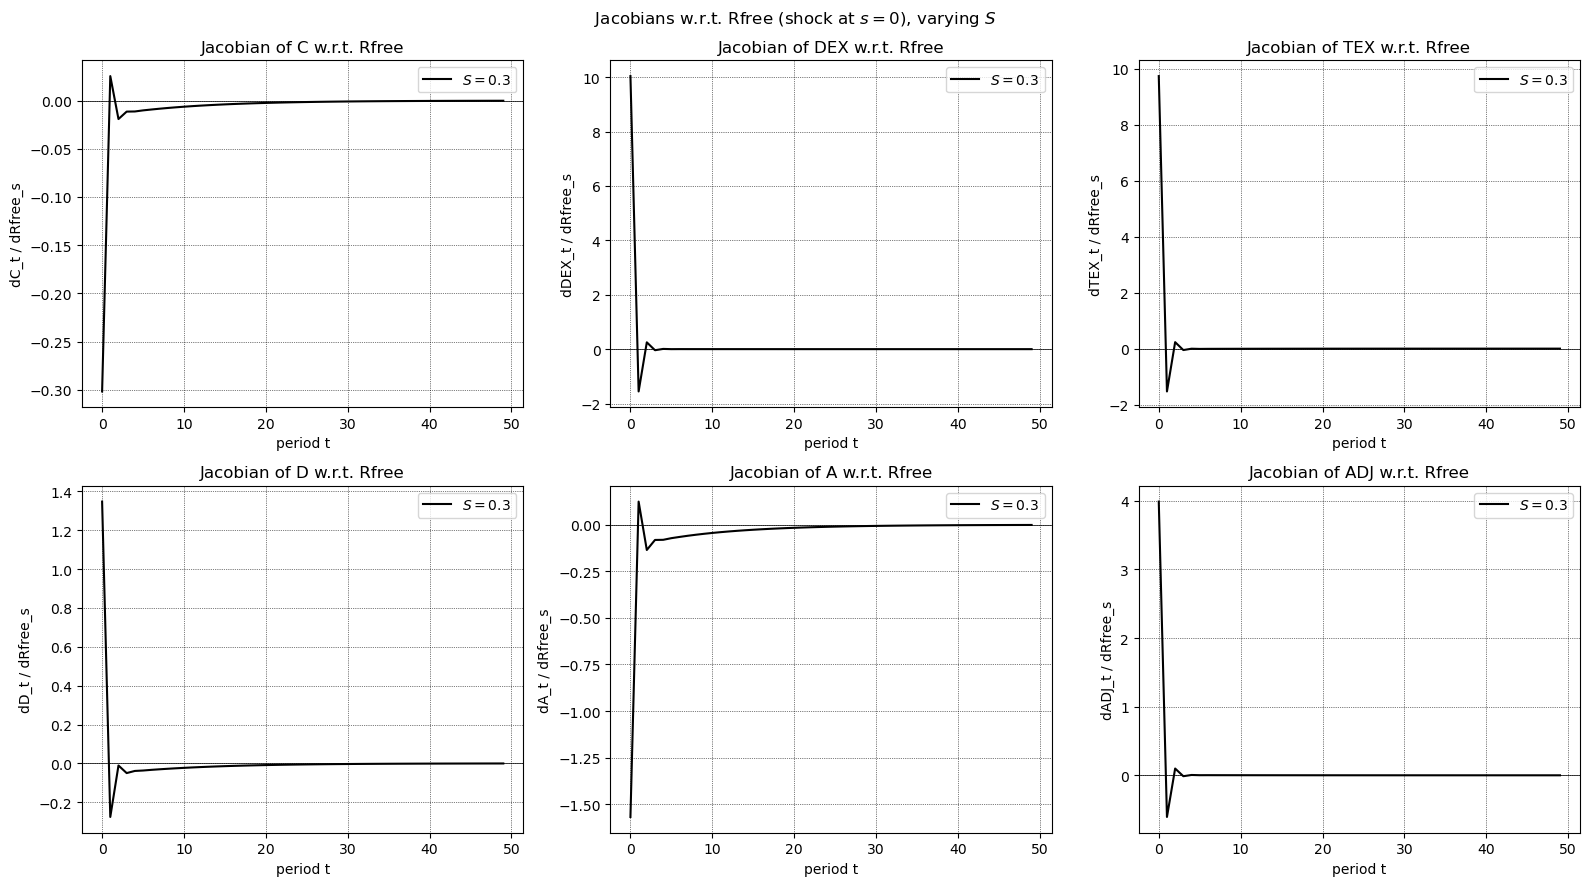

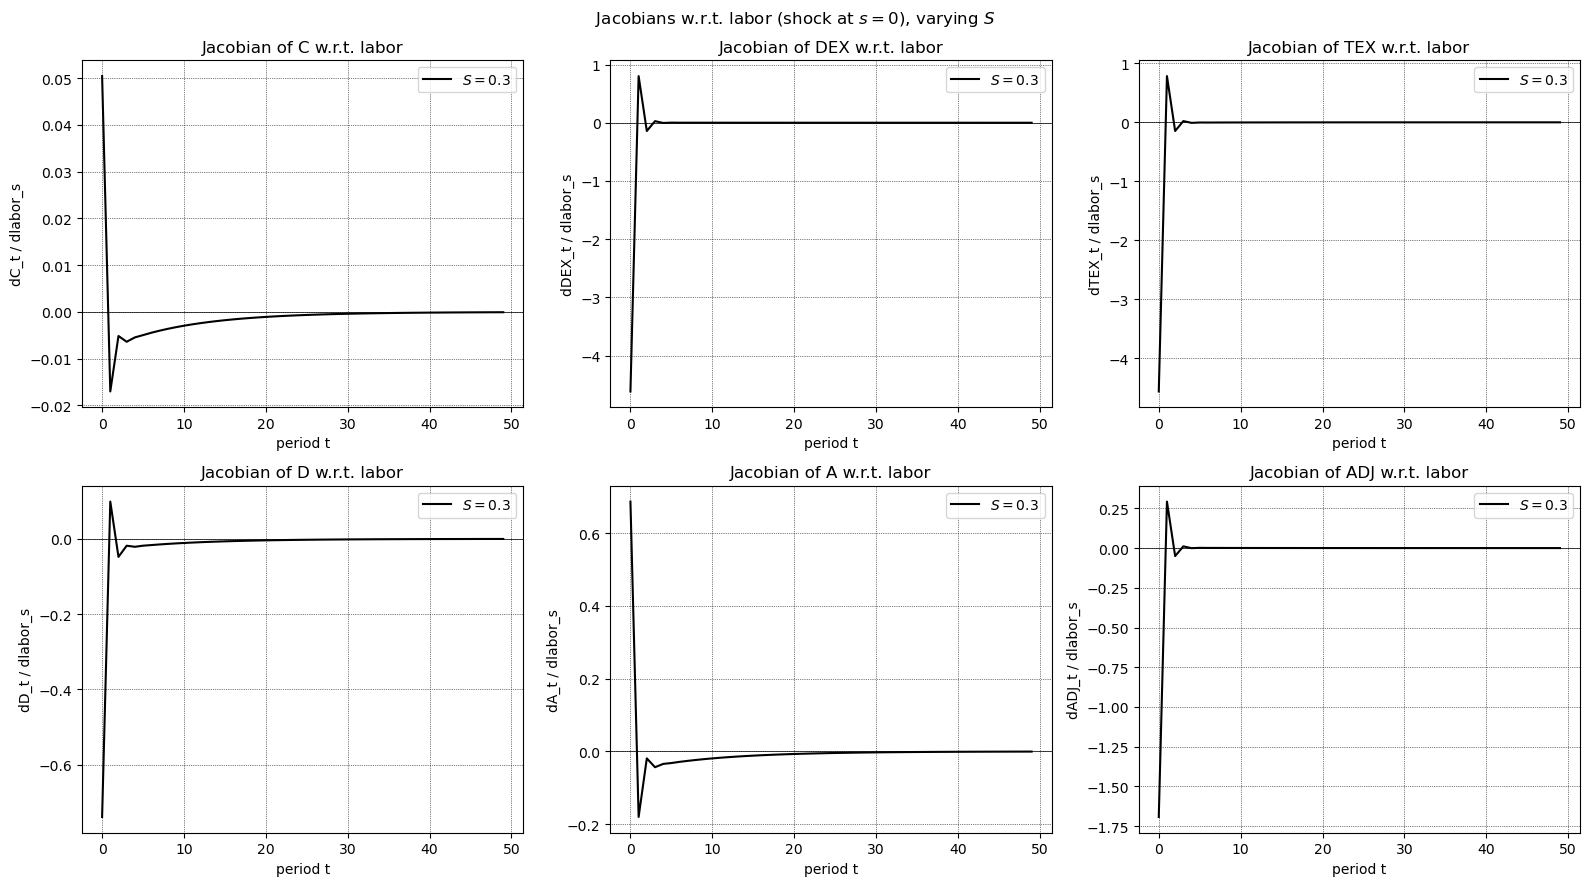

In [6]:
# Overlay Jacobians across parameter values (IRF to period-0 shock)
# Linestyles follow Figures_Durable.ipynb smoothing overlays.
shock_s = 0  # column of Jacobian = date of shock

# --- Rfree ---
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, name in zip(axes.flat, JAC_KEYS):
    for r, (color, ls) in zip(results, LINE_STYLES):
        J = r["jacobians_Rfree"][name]
        ax.plot(J[:, shock_s], color=color, linestyle=ls, label=r["label"])
    ax.axhline(0.0, color="k", lw=0.5)
    ax.set_title(f"Jacobian of {name} w.r.t. Rfree")
    ax.set_xlabel("period t")
    ax.set_ylabel(f"d{name}_t / dRfree_s")
    ax.grid(color="k", linestyle=":", linewidth=0.5)
    ax.legend(loc="best")
fig.suptitle(r"Jacobians w.r.t. Rfree (shock at $s=0$), varying $S$")
fig.tight_layout()
plt.show()

# --- labor ---
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, name in zip(axes.flat, JAC_KEYS):
    for r, (color, ls) in zip(results, LINE_STYLES):
        J = r["jacobians_labor"][name]
        ax.plot(J[:, shock_s], color=color, linestyle=ls, label=r["label"])
    ax.axhline(0.0, color="k", lw=0.5)
    ax.set_title(f"Jacobian of {name} w.r.t. labor")
    ax.set_xlabel("period t")
    ax.set_ylabel(f"d{name}_t / dlabor_s")
    ax.grid(color="k", linestyle=":", linewidth=0.5)
    ax.legend(loc="best")
fig.suptitle(r"Jacobians w.r.t. labor (shock at $s=0$), varying $S$")
fig.tight_layout()
plt.show()


In [7]:
# # Save steady states and Jacobians as separate pickles
# ss_payload = {
#     "channel": results[0]["channel"],
#     "param_name": results[0]["param_name"],
#     "param_col": results[0]["param_col"],
#     "param_values": [r["param"] for r in results],
#     "labels": [r["label"] for r in results],
#     "steady_states": {r["param"]: r["ss"] for r in results},
#     "kink_euler": {r["param"]: r["kink_euler"] for r in results},
#     "kink_euler_t": 0,
#     "ss_table": ss_table,
# }

# jac_meta = dict(
#     channel=results[0]["channel"],
#     param_name=results[0]["param_name"],
#     param_col=results[0]["param_col"],
#     param_values=[r["param"] for r in results],
#     labels=[r["label"] for r in results],
#     T=T,
#     shock_s_plotted=0,
# )

# jac_payload_Rfree = {
#     **jac_meta,
#     "shk_param": "Rfree",
#     "jacobians": {r["param"]: r["jacobians_Rfree"] for r in results},
# }
# jac_payload_labor = {
#     **jac_meta,
#     "shk_param": "labor",
#     "jacobians": {r["param"]: r["jacobians_labor"] for r in results},
# }

# ss_path = OUT_DIR / "DurableModel_Search_Inf_SS.pkl"
# jac_path_Rfree = OUT_DIR / "DurableModel_Search_Inf_Jacobians_Rfree.pkl"
# jac_path_labor = OUT_DIR / "DurableModel_Search_Inf_Jacobians_labor.pkl"
# with open(ss_path, "wb") as f:
#     pickle.dump(ss_payload, f)
# with open(jac_path_Rfree, "wb") as f:
#     pickle.dump(jac_payload_Rfree, f)
# with open(jac_path_labor, "wb") as f:
#     pickle.dump(jac_payload_labor, f)

# elapsed = time.time() - start_time
# print(f"Saved {ss_path.resolve()}")
# print(f"Saved {jac_path_Rfree.resolve()}")
# print(f"Saved {jac_path_labor.resolve()}")
# print("Done in", str(datetime.timedelta(seconds=elapsed)))


### Diagnostics


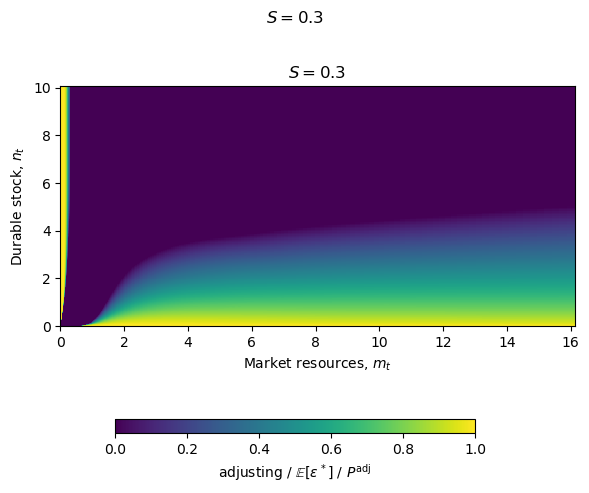

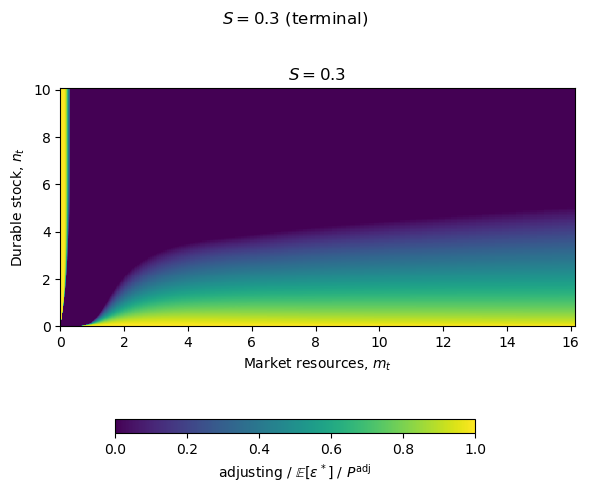

In [8]:
# 1. SS bands in solution [0]
title = param_labels[0]
plot_case_heatmaps([model], [title], 0, "Search_Inf_Test", suptitle=title)


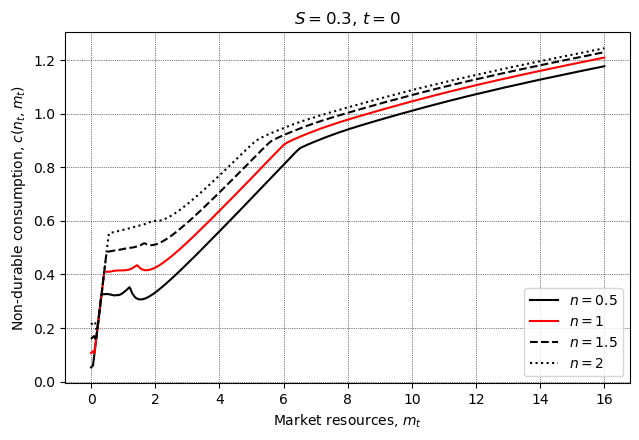

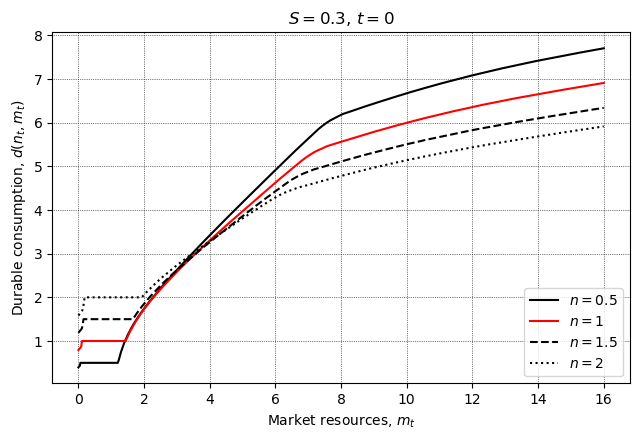

In [9]:
# 2. cFunc / dFunc for different n's
title = param_labels[0]
plot_combined_policies([model], [title], title, "Search_Inf_Test", t=0)


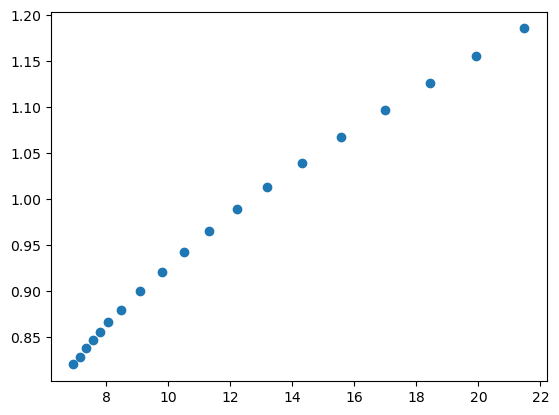

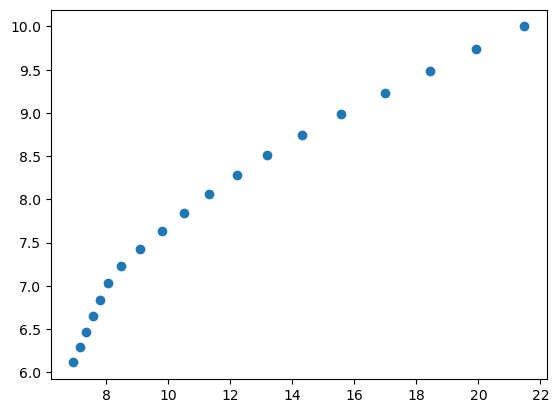

In [10]:
# 3. cFuncAdj scatter plot of post-FUES
plt.scatter(model.solution[0].xAdj_post_list, model.solution[0].cAdj_post_list)
plt.show()

plt.scatter(model.solution[0].xAdj_post_list, model.solution[0].dAdj_post_list)
plt.show()

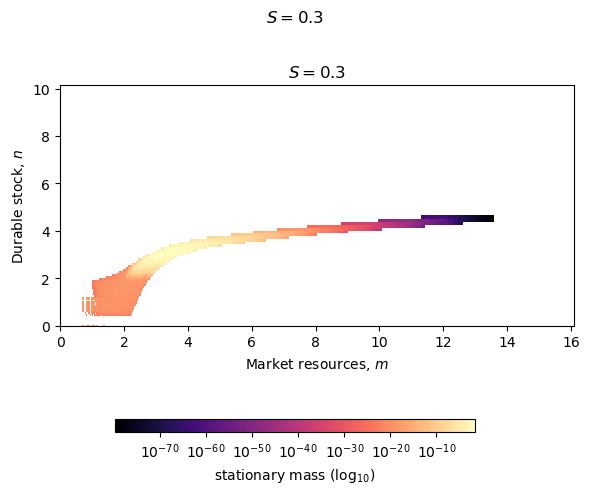

In [11]:
# 4. Ergodic distribution (after compute_steady_state)
title = param_labels[0]
plot_ergodic_heatmaps([model], [title], "Search_Inf_Test_erg.pdf", suptitle=title)


$S = 0.3$: E_mu[P(adj)]=0.066460 (ADJ_ss=0.066460); P(adj) in [0, 1]; mass P<=0.001: 0.0046, continuous (0.001<P<0.999): 0.9954, P>=0.999: 0.0000; share of ADJ flow from continuous band: 1.000


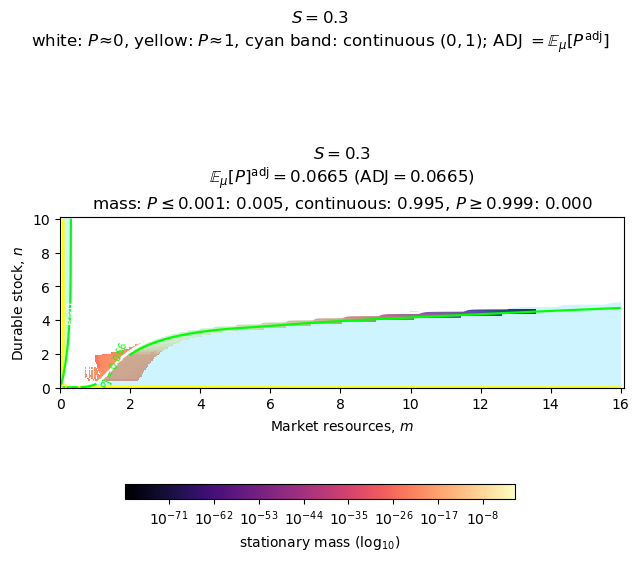

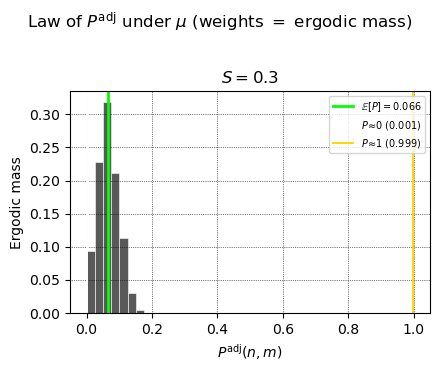

In [12]:
# 5. Ergodic mass overlaid with Ss adjusting contours (border mass)
# White / yellow lines: P≈0 and P≈1 frontiers; cyan shade: continuous (0,1) band
title = param_labels[0]
plot_ergodic_ss_overlay(
    [model], [title], "Search_Inf_Test_erg_Ss.pdf",
    suptitle=title, border=(1e-3, 1.0 - 1e-3),
)


---
## Interpolant vs cond SS and Jacobians

The default `compute_steady_state` / `calc_jacobian` interpolate the solver's
mixed policies and `adjusting` onto the histogram grid.

`compute_steady_state_cond` / `calc_jacobian_cond` interpolate only keeper /
adjuster *conditionals*, rebuild continuation values, and re-combine on that
grid (search / EV taste / hard max).


In [13]:
# Snapshot interpolant SS / Jacobians, then recompute with the cond method.
ss_interp = dict(results[-1]["ss"])
jac_R_interp = results[-1]["jacobians_Rfree"]
jac_L_interp = results[-1]["jacobians_labor"]
title = param_labels[0]

print("Computing cond SS and Jacobians ...")
model.compute_steady_state_cond()
ss_cond = dict(
    C=float(model.C_ss),
    D=float(model.D_ss),
    DEX=float(model.DEX_ss),
    TEX=float(model.TEX_ss),
    A=float(model.A_ss),
    ADJ=float(model.ADJ_ss),
)
J_C, J_DEX, J_TEX, J_D, J_A, J_ADJ = model.calc_jacobian_cond("Rfree", T)
jac_R_cond = dict(C=J_C, DEX=J_DEX, TEX=J_TEX, D=J_D, A=J_A, ADJ=J_ADJ)
J_C, J_DEX, J_TEX, J_D, J_A, J_ADJ = model.calc_jacobian_cond("labor", T)
jac_L_cond = dict(C=J_C, DEX=J_DEX, TEX=J_TEX, D=J_D, A=J_A, ADJ=J_ADJ)
print("Cond SS / Jacobians done.")

ss_cmp = pd.DataFrame(
    {
        "interp": [ss_interp[k] for k in SS_KEYS],
        "cond": [ss_cond[k] for k in SS_KEYS],
    },
    index=SS_KEYS,
)
ss_cmp["diff"] = ss_cmp["cond"] - ss_cmp["interp"]
ss_cmp["pct"] = 100.0 * ss_cmp["diff"] / ss_cmp["interp"].replace(0.0, np.nan)
print(f"Steady-state: interpolant vs cond  ({title})")
display(ss_cmp.style.format("{:.6f}"))


Computing cond SS and Jacobians ...


c:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\scipy\sparse\_index.py:151: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray(i, j, x)
c:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
c:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel_Fast.py:1177: RuntimeWarning: divide by zero encountered in power
  * (C ** (self.alpha * (1.0 - self.CRRA)))
c:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel_Fast.py:1170: RuntimeWarning: divide by zero encountered in power
  * C ** (self.alpha * (1.0 - self.CRRA) - 1.0)


Cond SS / Jacobians done.
Steady-state: interpolant vs cond  ($S = 0.3$)


,interp,cond,diff,pct
C,0.841229,0.840981,-0.000249,-0.029541
D,3.248459,3.250944,0.002485,0.076505
DEX,0.162423,0.162547,0.000124,0.076505
TEX,1.003652,1.003528,-0.000124,-0.012379
A,2.431390,2.426961,-0.004429,-0.182178
ADJ,0.066460,0.066665,0.000205,0.308016


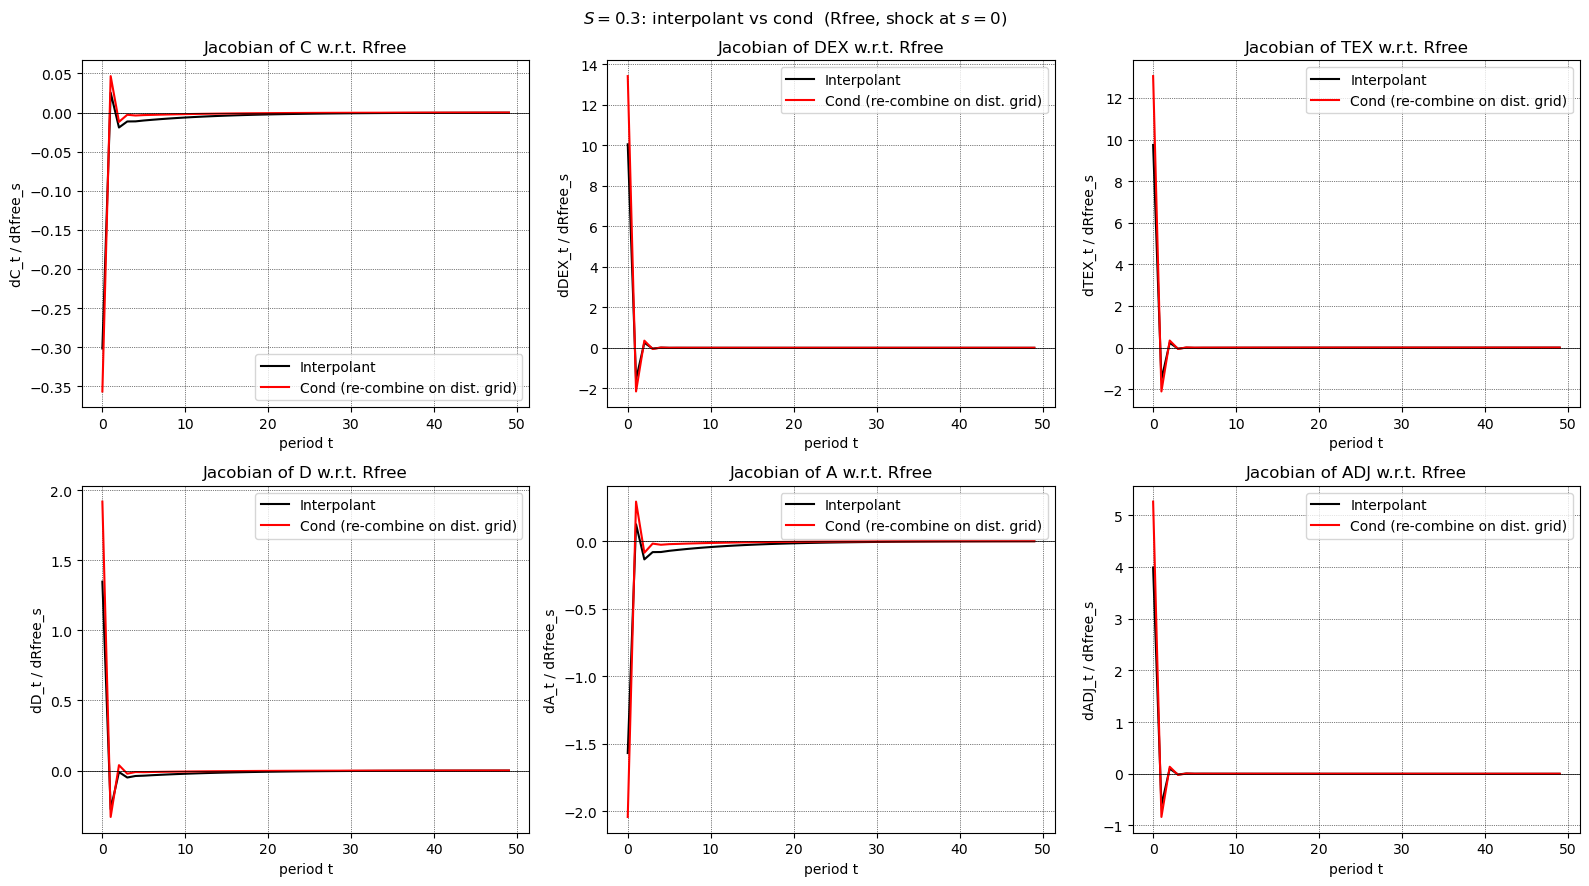

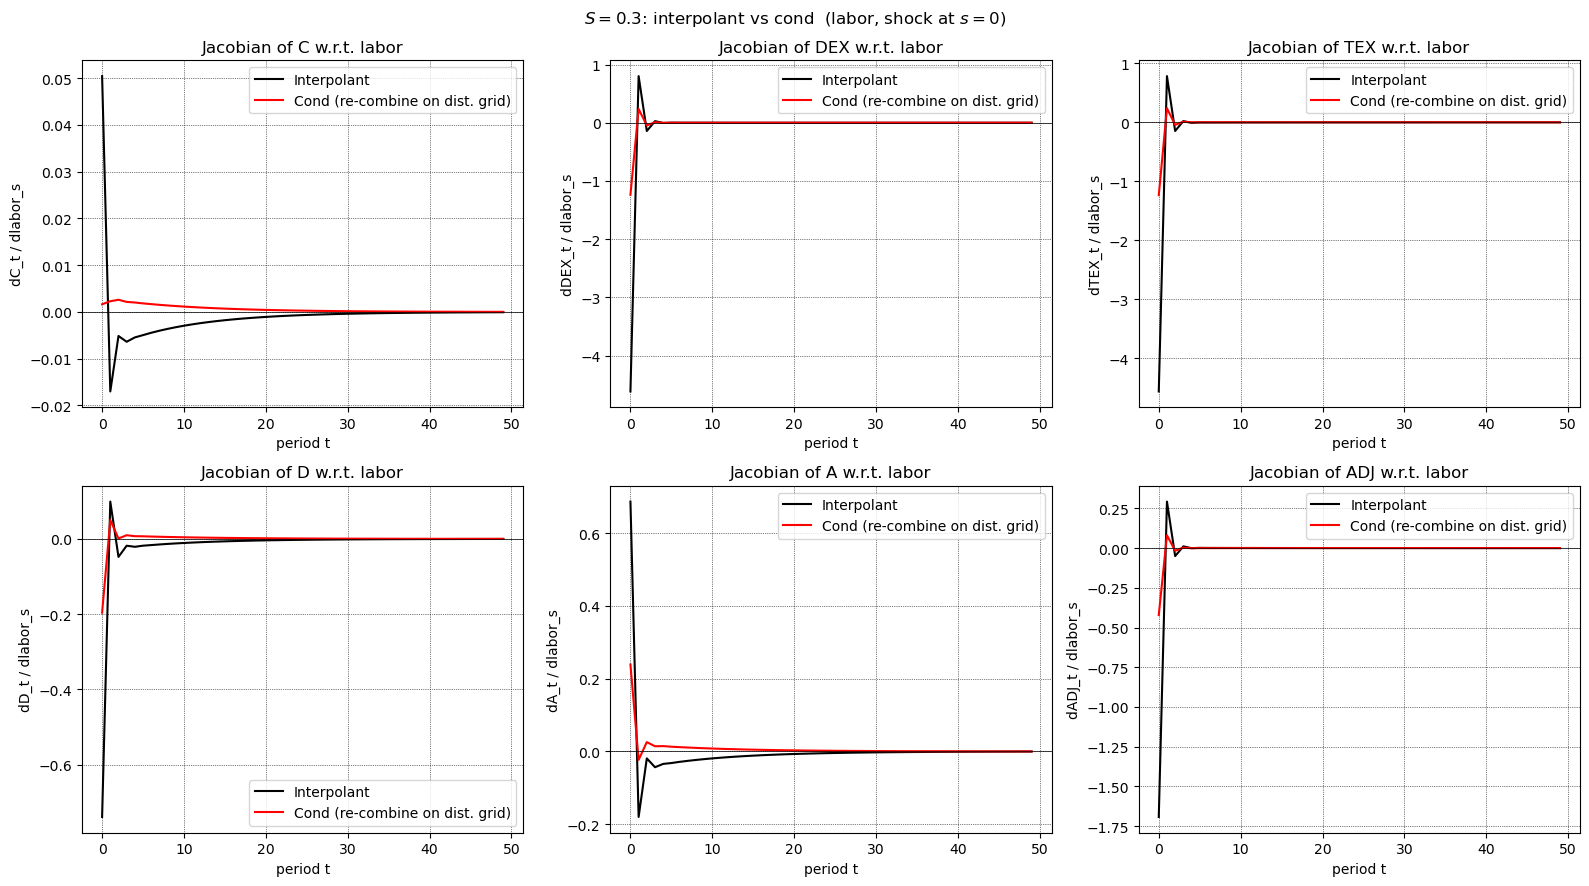

In [14]:
# Overlay interpolant vs cond Jacobians (IRF to period-0 shock)
shock_s = 0

def _plot_jac_compare(jac_interp, jac_cond, shk_name):
    fig, axes = plt.subplots(2, 3, figsize=(16, 9))
    versions = [
        (jac_interp, "Interpolant", LINE_STYLES[0]),
        (jac_cond, "Cond (re-combine on dist. grid)", LINE_STYLES[1]),
    ]
    for ax, name in zip(axes.flat, JAC_KEYS):
        for Jdict, lab, (color, ls) in versions:
            ax.plot(Jdict[name][:, shock_s], color=color, linestyle=ls, label=lab)
        ax.axhline(0.0, color="k", lw=0.5)
        ax.set_title(f"Jacobian of {name} w.r.t. {shk_name}")
        ax.set_xlabel("period t")
        ax.set_ylabel(f"d{name}_t / d{shk_name}_s")
        ax.grid(color="k", linestyle=":", linewidth=0.5)
        ax.legend(loc="best")
    fig.suptitle(rf"{title}: interpolant vs cond  ({shk_name}, shock at $s=0$)")
    fig.tight_layout()
    plt.show()

_plot_jac_compare(jac_R_interp, jac_R_cond, "Rfree")
_plot_jac_compare(jac_L_interp, jac_L_cond, "labor")


---
## Step-by-step `calc_jacobian_cond` (fake news)

Inlined from `DurableModel.py` (`calc_jacobian_cond`), using histogram-grid
re-combined keeper/adjuster policies. After each step, plots show where the
S,s / discrete-choice border moves by $O(1)$ for a shock of size `jac_dx`, so
$(\Delta \mathrm{policy})/dx$ spikes and the Jacobian blows up.

Index map for the finite-horizon agent (shock at period $T-1$):

- $k=0$: SS vs SS (zero)
- $k=1$: contemporaneous shocked period (`a_t[T-1]`)
- $k=2$: one-period news / anticipation (`a_t[T-2]`)

Requires the solved `model` from above. Change `shk_param` in the next cell
(`"labor"` or `"Rfree"`) if you want the other shock.


In [15]:
# Rebuild the histogram-grid re-combined SS used by calc_jacobian_cond.
print("Rebuilding cond SS via compute_steady_state_cond() ...")
model.compute_steady_state_cond()
print("SS ready.  _ss_method =", model._ss_method)

from utility import J_from_F

# Shock used for the inlined walkthrough (same as calc_jacobian's shk_param).
shk_param = "labor"

print(f"Walkthrough shock: {shk_param}")
print(f"Horizon T = {T},  jac_dx = {model.jac_dx}")
print(f"SS method currently on model: {getattr(model, '_ss_method', None)}")


def _reshape_state(vec):
    return np.asarray(vec, dtype=float).reshape(len(model.dist_nGrid), len(model.dist_mGrid))


def _heatmap(Z, title, diverging=True, vmin=None, vmax=None, cmap=None, cbar=None):
    Z = np.asarray(Z, dtype=float)
    if Z.ndim == 1:
        Z = _reshape_state(Z)
    fig, ax = plt.subplots(figsize=(6.0, 4.5))
    if diverging:
        lim = np.nanmax(np.abs(Z))
        lim = 1.0 if (not np.isfinite(lim) or lim == 0.0) else lim
        pcm = ax.pcolormesh(
            model.dist_mGrid, model.dist_nGrid, Z,
            cmap=cmap or "RdBu_r", shading="auto", vmin=-lim, vmax=lim,
        )
    else:
        kw = dict(cmap=cmap or "viridis", shading="auto")
        if vmin is not None:
            kw["vmin"] = vmin
        if vmax is not None:
            kw["vmax"] = vmax
        pcm = ax.pcolormesh(model.dist_mGrid, model.dist_nGrid, Z, **kw)
    ax.set_xlabel(r"Market resources, $m$")
    ax.set_ylabel(r"Durable stock, $n$")
    ax.set_title(title)
    fig.colorbar(pcm, ax=ax, label=cbar)
    fig.tight_layout()
    plt.show()


def _heatmaps_row(Zs, titles, diverging=False, vmin=None, vmax=None, cmap=None, cbar=None, suptitle=None):
    n = len(Zs)
    fig, axes = plt.subplots(1, n, figsize=(4.6 * n, 4.2), sharex=True, sharey=True)
    if n == 1:
        axes = np.array([axes])
    last = None
    for ax, Z, title in zip(axes, Zs, titles):
        Z = np.asarray(Z, dtype=float)
        if Z.ndim == 1:
            Z = _reshape_state(Z)
        if diverging:
            lim = np.nanmax(np.abs(Z))
            lim = 1.0 if (not np.isfinite(lim) or lim == 0.0) else lim
            last = ax.pcolormesh(
                model.dist_mGrid, model.dist_nGrid, Z,
                cmap=cmap or "RdBu_r", shading="auto", vmin=-lim, vmax=lim,
            )
        else:
            kw = dict(cmap=cmap or "viridis", shading="auto")
            if vmin is not None:
                kw["vmin"] = vmin
            if vmax is not None:
                kw["vmax"] = vmax
            last = ax.pcolormesh(model.dist_mGrid, model.dist_nGrid, Z, **kw)
        ax.set_title(title)
        ax.set_xlabel(r"$m$")
        ax.set_ylabel(r"$n$")
    if suptitle:
        fig.suptitle(suptitle, y=1.02)
    fig.tight_layout()
    fig.colorbar(last, ax=axes.tolist(), shrink=0.85, label=cbar)
    plt.show()


def _slices_d_dx(pol_ss, pol_t, ylabel, title):
    fig, ax = plt.subplots(figsize=(7.0, 4.5))
    n_grid = np.asarray(model.dist_nGrid)
    m = np.asarray(model.dist_mGrid)
    d = (np.asarray(pol_t, dtype=float) - np.asarray(pol_ss, dtype=float)) / dx
    for n0, (color, ls) in zip(N_SHOW_DEFAULT, N_LINE_STYLES):
        i_n = int(np.argmin(np.abs(n_grid - n0)))
        ax.plot(m, d[i_n], color=color, linestyle=ls, label=rf"$n={n0:g}$")
    ax.axhline(0.0, color="k", lw=0.5)
    ax.set_xlabel(r"Market resources, $m$")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(color="k", linestyle=":", linewidth=0.5)
    ax.legend(loc="best")
    fig.tight_layout()
    plt.show()


def _jump_stats(pol_ss, pol_t, name):
    d = (np.asarray(pol_t, dtype=float) - np.asarray(pol_ss, dtype=float)) / dx
    absd = np.abs(d)
    print(
        f"{name:4s}: max|d/dx|={np.nanmax(absd):.4e}  "
        f"mean|d/dx|={np.nanmean(absd):.4e}  "
        f"p99|d/dx|={np.nanpercentile(absd, 99):.4e}"
    )
    return d


def _plot_series(series, title, ylabel=None):
    fig, axes = plt.subplots(2, 3, figsize=(16, 8))
    for ax, name in zip(axes.flat, JAC_KEYS):
        ax.plot(series[name], color="k")
        ax.axhline(0.0, color="k", lw=0.5)
        ax.set_title(name)
        ax.set_xlabel("k (news horizon)")
        ax.set_ylabel(ylabel or name)
        ax.grid(color="k", linestyle=":", linewidth=0.5)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


Rebuilding cond SS via compute_steady_state_cond() ...
SS ready.  _ss_method = cond
Walkthrough shock: labor
Horizon T = 50,  jac_dx = 0.0001
SS method currently on model: cond


c:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\scipy\sparse\_index.py:151: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray(i, j, x)


### Finite-horizon agent, shock at $T-1$

Build a $T$-period agent seeded by the SS solution, perturb `shk_param` only in
period $T-1$, then re-combine keeper/adjuster conditionals on the histogram grid
(`calc_transition_matrix_dur_cond`).


In [16]:
# Exact body of DurableModel.py :: calc_jacobian_cond  (finite-horizon agent)
T = int(T)
dx = model.jac_dx
ss_val = model._as_scalar(getattr(model, shk_param))

a_ss = model.aPol_Grid
c_ss = model.cPol_Grid
d_ss = model.dPol_Grid
dex_ss = model.dexPol_Grid
adj_ss = model.adjPol_Grid
tranmat_ss = model.tran_matrix
Dist_ss = model.vec_erg_dstn.T

print(f"Solving finite-horizon agent, shock {shk_param} at period T-1 = {T-1} ...")
FinHorizonAgent = model._make_finite_agent(T)
path = [ss_val] * T
path[T - 1] = ss_val + dx
FinHorizonAgent._solve_perturbed_finite({shk_param: path})
FinHorizonAgent.define_distribution_grid_dur()
FinHorizonAgent.calc_transition_matrix_dur_cond(param_path={shk_param: path})

a_t = list(FinHorizonAgent.aPol_Grid) + [model.a_ss]
c_t = list(FinHorizonAgent.cPol_Grid) + [model.c_ss]
d_t = list(FinHorizonAgent.dPol_Grid) + [model.d_ss]
dex_t = list(FinHorizonAgent.dexPol_Grid) + [model.dex_ss]
adj_t = list(FinHorizonAgent.adjPol_Grid) + [model.adj_ss]
tranmat_t = list(FinHorizonAgent.tran_matrix) + [tranmat_ss]
print("Finite-horizon policies on the histogram grid are ready.")


Solving finite-horizon agent, shock labor at period T-1 = 49 ...


c:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
c:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel_Fast.py:1177: RuntimeWarning: divide by zero encountered in power
  * (C ** (self.alpha * (1.0 - self.CRRA)))
c:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel_Fast.py:1170: RuntimeWarning: divide by zero encountered in power
  * C ** (self.alpha * (1.0 - self.CRRA) - 1.0)


Finite-horizon policies on the histogram grid are ready.


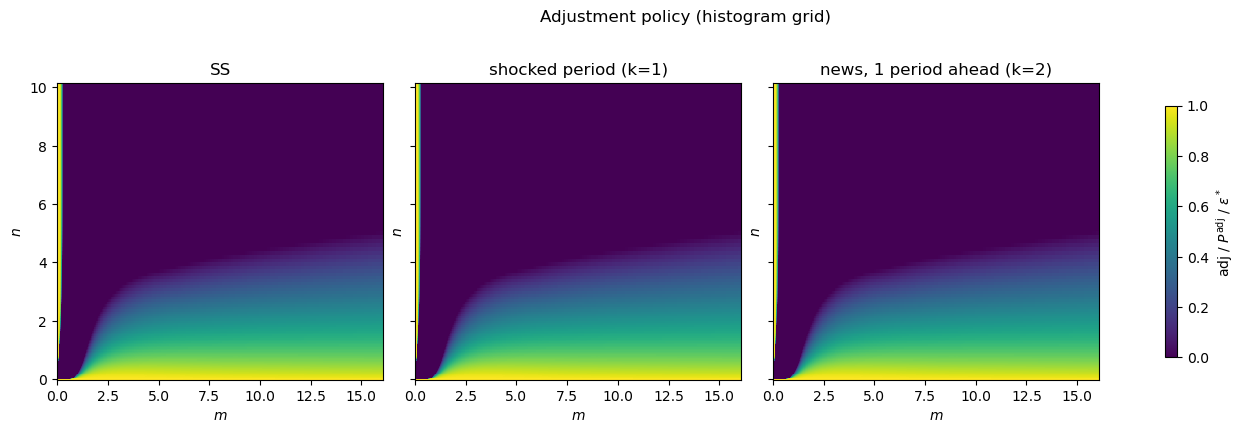

Finite-difference policy slopes (k=1, contemporaneous):
C   : max|d/dx|=4.3960e+00  mean|d/dx|=3.4385e-01  p99|d/dx|=3.6360e+00
D   : max|d/dx|=9.4620e+00  mean|d/dx|=8.1436e-01  p99|d/dx|=7.3145e+00
A   : max|d/dx|=9.3041e+00  mean|d/dx|=9.8815e-01  p99|d/dx|=7.0875e+00
DEX : max|d/dx|=9.4620e+00  mean|d/dx|=8.1436e-01  p99|d/dx|=7.3145e+00
ADJ : max|d/dx|=1.1525e+01  mean|d/dx|=1.5339e-01  p99|d/dx|=3.3376e+00


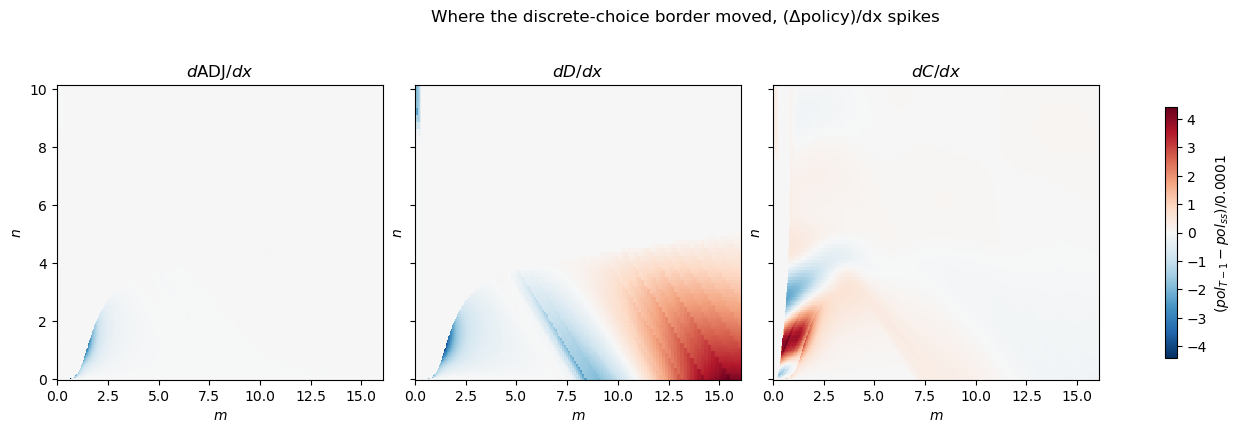

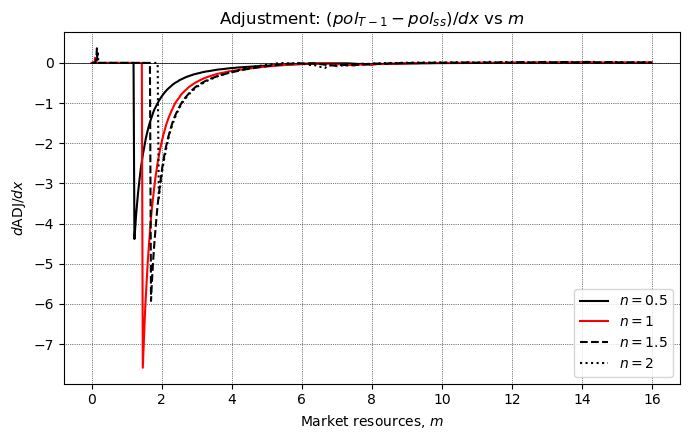

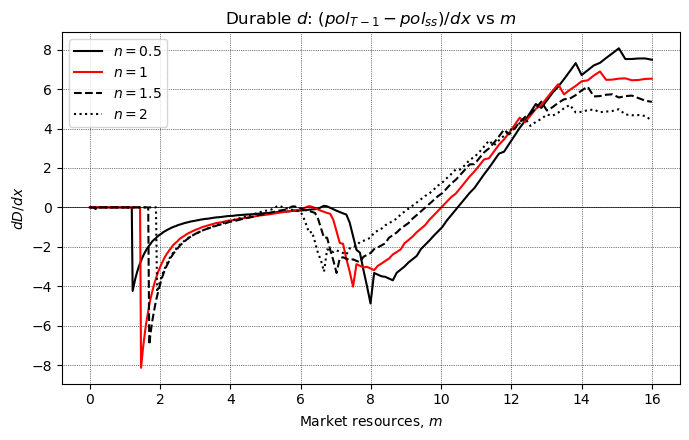

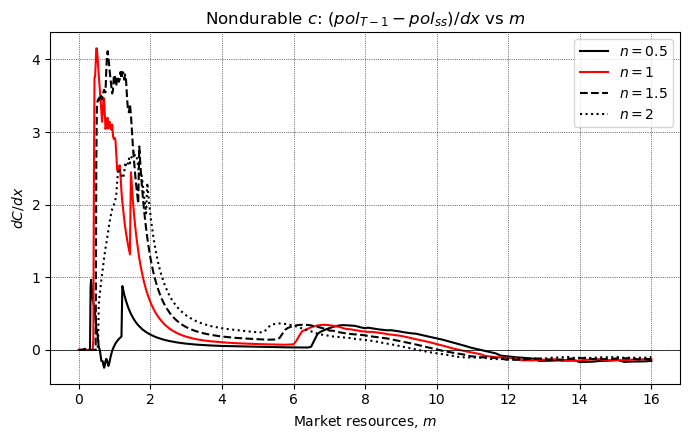

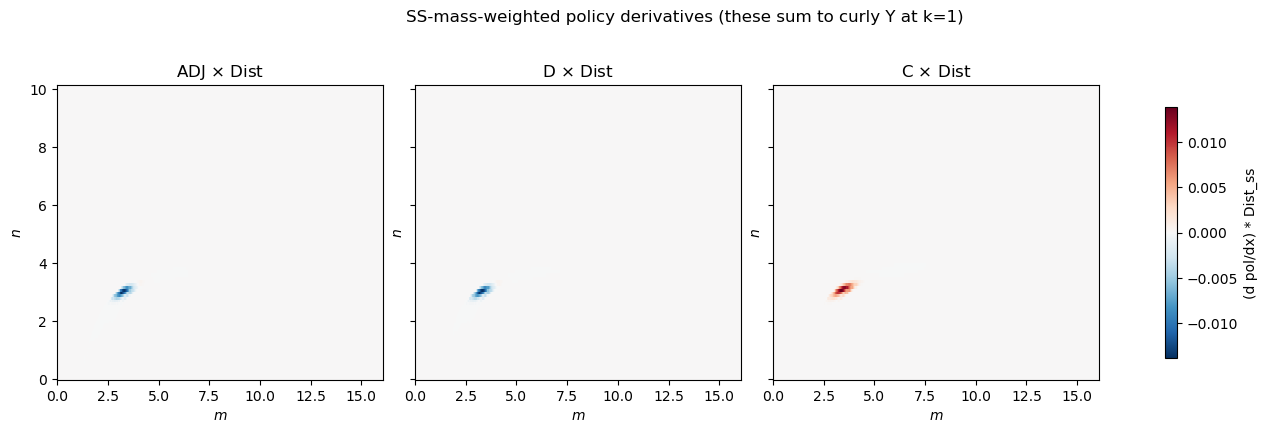

Conditional finite-difference slopes (k=1 vs SS):
  Adjuster:
cAdj: max|d/dx|=3.2080e-01  mean|d/dx|=8.9701e-02  p99|d/dx|=3.1646e-01
dAdj: max|d/dx|=9.6742e+00  mean|d/dx|=1.9488e+00  p99|d/dx|=9.1347e+00
aAdj: max|d/dx|=9.5210e+00  mean|d/dx|=1.8797e+00  p99|d/dx|=8.9690e+00
  Keeper:
cKeep: max|d/dx|=4.3960e+00  mean|d/dx|=3.4892e-01  p99|d/dx|=3.6360e+00
dKeep: max|d/dx|=0.0000e+00  mean|d/dx|=0.0000e+00  p99|d/dx|=0.0000e+00
aKeep: max|d/dx|=4.3960e+00  mean|d/dx|=3.4892e-01  p99|d/dx|=3.6360e+00


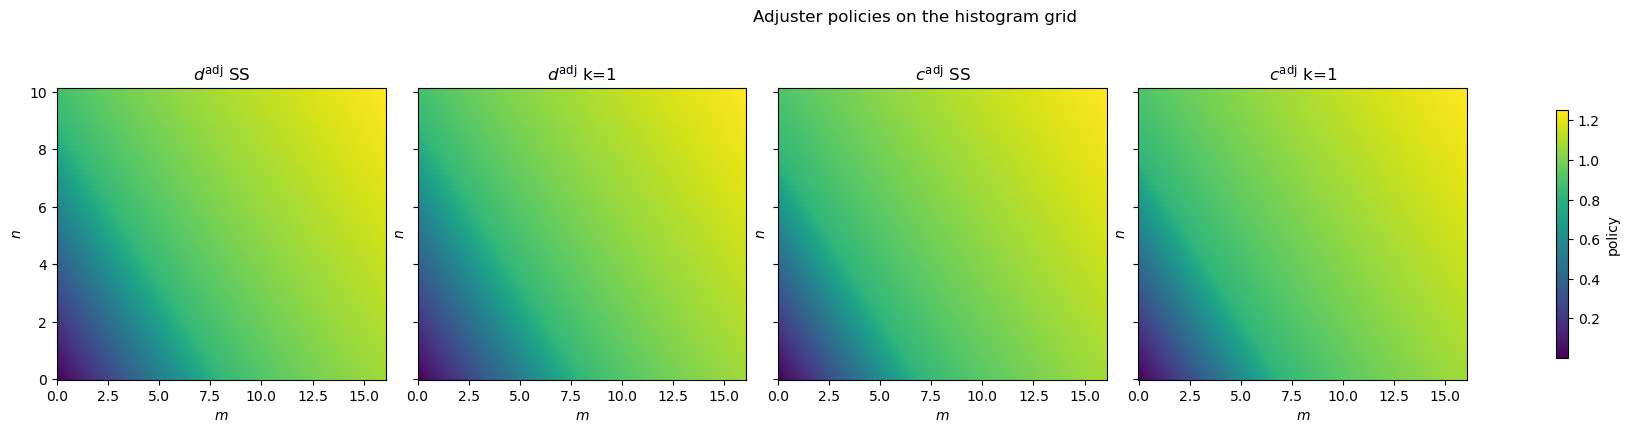

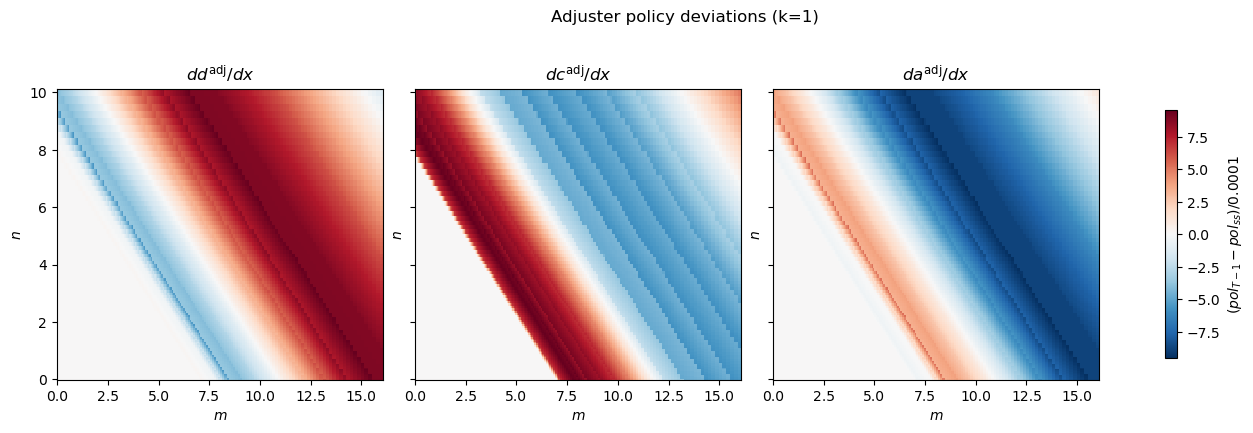

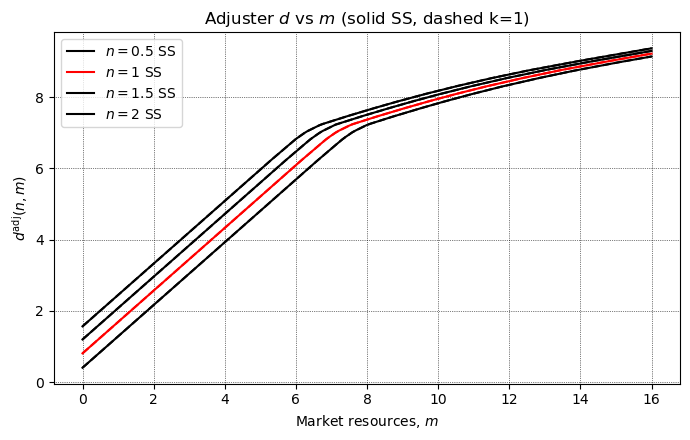

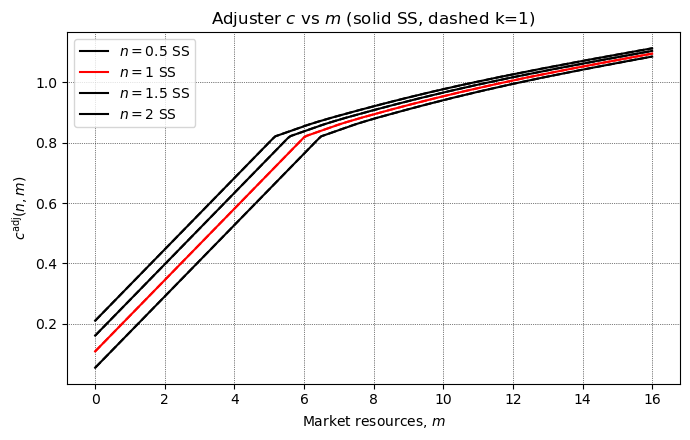

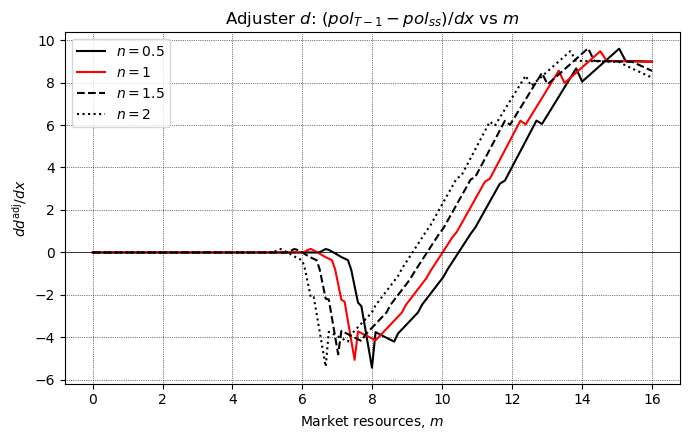

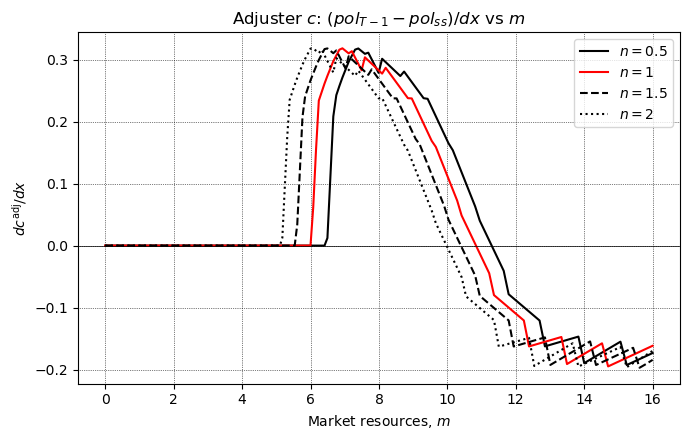

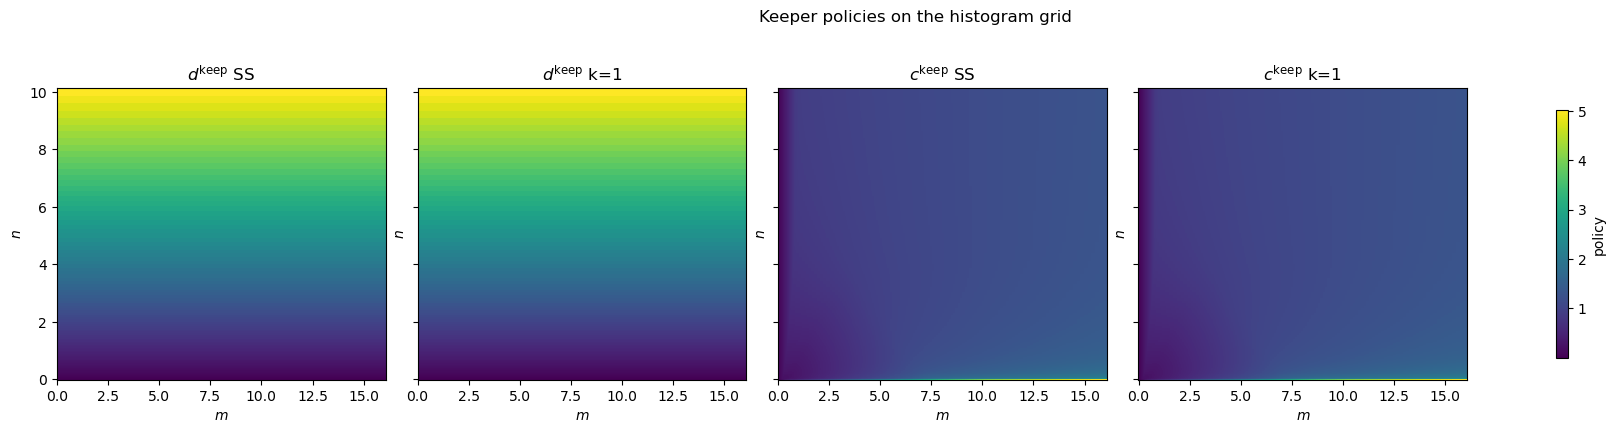

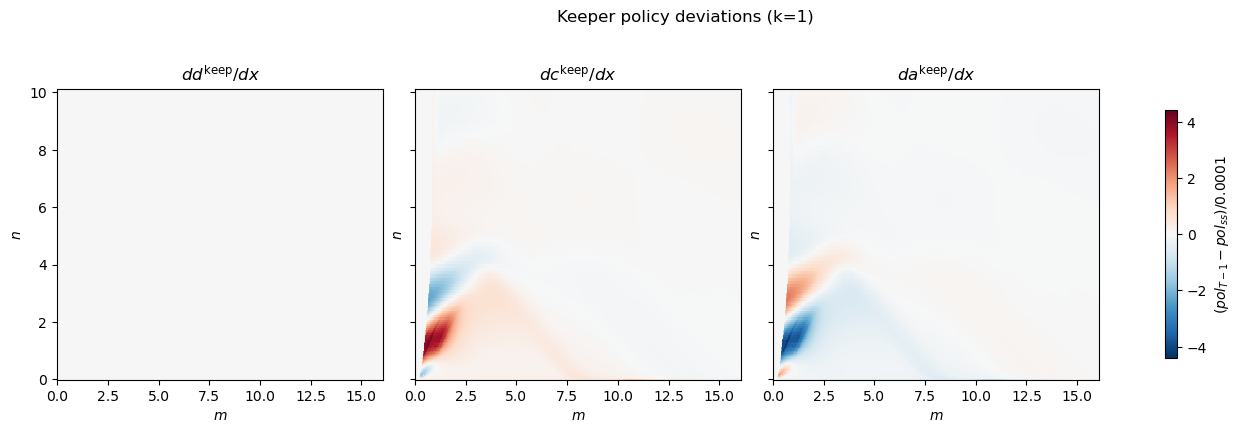

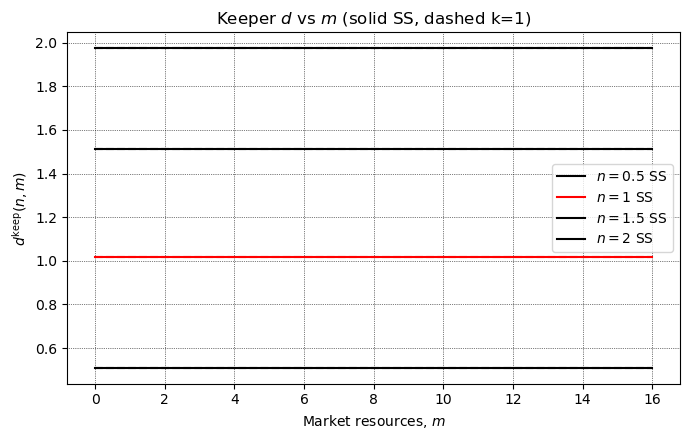

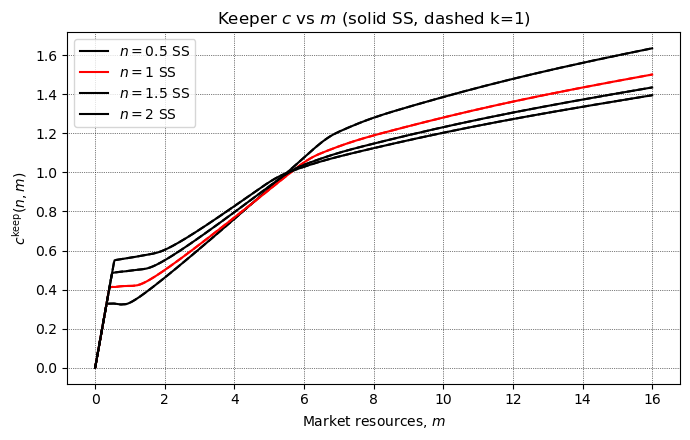

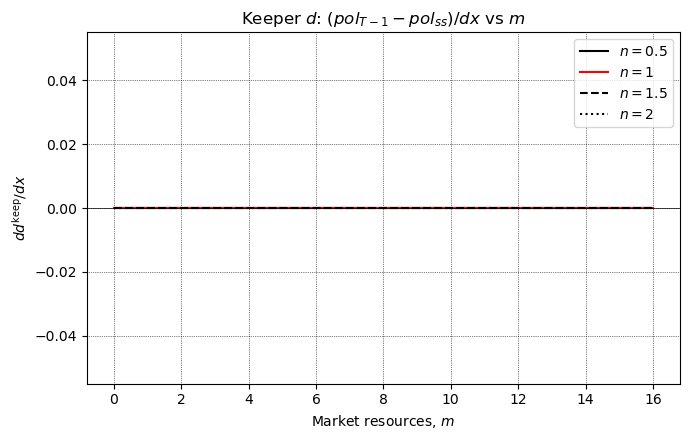

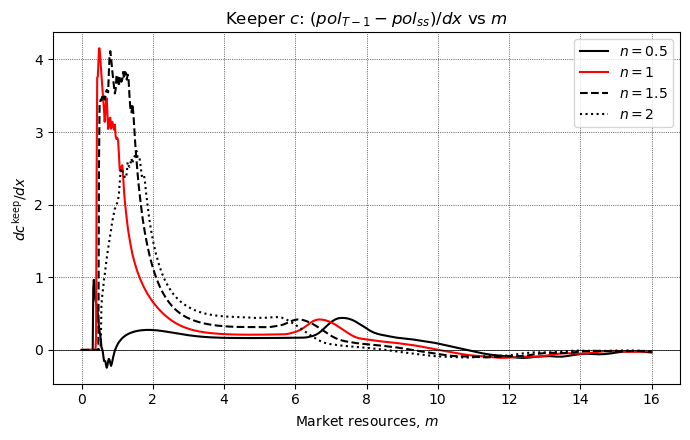

In [17]:
# Policy grids on the histogram: index T-k in curly-Y language.
#   k=0 -> a_t[T]   = SS (no deviation)
#   k=1 -> a_t[T-1] = contemporaneous shocked period
#   k=2 -> a_t[T-2] = one-period news / anticipation
adj_k0, adj_k1, adj_k2 = adj_t[T], adj_t[T - 1], adj_t[T - 2]
c_k1, d_k1, a_k1, dex_k1 = c_t[T - 1], d_t[T - 1], a_t[T - 1], dex_t[T - 1]

_heatmaps_row(
    [adj_ss, adj_k1, adj_k2],
    ["SS", "shocked period (k=1)", "news, 1 period ahead (k=2)"],
    diverging=False, vmin=0.0, vmax=1.0, cmap="viridis",
    cbar=r"adj / $P^{\mathrm{adj}}$ / $\varepsilon^*$",
    suptitle="Adjustment policy (histogram grid)",
)

print("Finite-difference policy slopes (k=1, contemporaneous):")
dc = _jump_stats(c_ss, c_k1, "C")
dd = _jump_stats(d_ss, d_k1, "D")
da = _jump_stats(a_ss, a_k1, "A")
ddex = _jump_stats(dex_ss, dex_k1, "DEX")
dadj = _jump_stats(adj_ss, adj_k1, "ADJ")

_heatmaps_row(
    [dadj, dd, dc],
    [r"$d\mathrm{ADJ}/dx$", r"$dD/dx$", r"$dC/dx$"],
    diverging=True,
    cbar=rf"$(pol_{{T-1}} - pol_{{ss}}) / {dx:g}$",
    suptitle="Where the discrete-choice border moved, (Δpolicy)/dx spikes",
)

_slices_d_dx(adj_ss, adj_k1, r"$d\mathrm{ADJ}/dx$", r"Adjustment: $(pol_{T-1}-pol_{ss})/dx$ vs $m$")
_slices_d_dx(d_ss, d_k1, r"$dD/dx$", r"Durable $d$: $(pol_{T-1}-pol_{ss})/dx$ vs $m$")
_slices_d_dx(c_ss, c_k1, r"$dC/dx$", r"Nondurable $c$: $(pol_{T-1}-pol_{ss})/dx$ vs $m$")

# Mass-weighted contributions: spikes only blow up aggregates if Dist_ss sits on them.
mass = _reshape_state(Dist_ss)
_heatmaps_row(
    [dadj * mass, dd * mass, dc * mass],
    [r"ADJ $\times$ Dist", r"D $\times$ Dist", r"C $\times$ Dist"],
    diverging=True,
    cbar="(d pol/dx) * Dist_ss",
    suptitle="SS-mass-weighted policy derivatives (these sum to curly Y at k=1)",
)

# Conditional keeper / adjuster policies on the histogram grid (same interpolation
# as DurableModel._search_on_dist_grid). Total mixed policies above can jump when
# the discrete border moves; these conditionals are the intensive-margin objects.
nGrid, mGrid, n_aux, m_aux = model._nm_dist_mesh()
shape = n_aux.shape
tau_nm = model.tau_func(n_aux + m_aux)
x_aux = np.clip(m_aux + (1.0 - tau_nm) * n_aux, 0.0, None)
x_flat = x_aux.ravel()
p0 = float(np.asarray(model.PriceShkVals, dtype=float)[0])


def _cond_on_dist(sol):
    cKeep = np.clip(np.asarray(sol.cFuncKeep(n_aux, m_aux), dtype=float), 0.0, None)
    dKeep = np.asarray(sol.dFuncKeep(n_aux, m_aux), dtype=float)
    aKeep = np.maximum(m_aux - cKeep, 0.0)
    c_list = getattr(sol, "cFuncAdj_1d_list", None)
    d_list = getattr(sol, "dFuncAdj_1d_list", None)
    if c_list is not None:
        cAdj = np.maximum(np.asarray(c_list[0](x_flat), dtype=float), 0.0).reshape(shape)
        dAdj = np.maximum(np.asarray(d_list[0](x_flat), dtype=float), 0.0).reshape(shape)
    else:
        cAdj = np.maximum(np.asarray(sol.cFuncAdj(n_aux, m_aux), dtype=float), 0.0)
        dAdj = np.maximum(np.asarray(sol.dFuncAdj(n_aux, m_aux), dtype=float), 0.0)
    aAdj = np.maximum(x_aux - cAdj - p0 * dAdj, 0.0)
    return dict(cKeep=cKeep, dKeep=dKeep, aKeep=aKeep, cAdj=cAdj, dAdj=dAdj, aAdj=aAdj)


def _slices_levels(pol_ss, pol_t, ylabel, title):
    fig, ax = plt.subplots(figsize=(7.0, 4.5))
    n_grid = np.asarray(model.dist_nGrid)
    m = np.asarray(model.dist_mGrid)
    for n0, (color, ls) in zip(N_SHOW_DEFAULT, N_LINE_STYLES):
        i_n = int(np.argmin(np.abs(n_grid - n0)))
        ax.plot(m, np.asarray(pol_ss)[i_n], color=color, linestyle="-", label=rf"$n={n0:g}$ SS")
        ax.plot(m, np.asarray(pol_t)[i_n], color=color, linestyle="--")
    ax.set_xlabel(r"Market resources, $m$")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(color="k", linestyle=":", linewidth=0.5)
    ax.legend(loc="best")
    fig.tight_layout()
    plt.show()


cond_ss = _cond_on_dist(model.solution[0])
cond_k1 = _cond_on_dist(FinHorizonAgent.solution[T - 1])

print("Conditional finite-difference slopes (k=1 vs SS):")
print("  Adjuster:")
_jump_stats(cond_ss["cAdj"], cond_k1["cAdj"], "cAdj")
_jump_stats(cond_ss["dAdj"], cond_k1["dAdj"], "dAdj")
_jump_stats(cond_ss["aAdj"], cond_k1["aAdj"], "aAdj")
print("  Keeper:")
_jump_stats(cond_ss["cKeep"], cond_k1["cKeep"], "cKeep")
_jump_stats(cond_ss["dKeep"], cond_k1["dKeep"], "dKeep")
_jump_stats(cond_ss["aKeep"], cond_k1["aKeep"], "aKeep")

ddAdj = (np.asarray(cond_k1["dAdj"]) - np.asarray(cond_ss["dAdj"])) / dx
dcAdj = (np.asarray(cond_k1["cAdj"]) - np.asarray(cond_ss["cAdj"])) / dx
daAdj = (np.asarray(cond_k1["aAdj"]) - np.asarray(cond_ss["aAdj"])) / dx
ddKeep = (np.asarray(cond_k1["dKeep"]) - np.asarray(cond_ss["dKeep"])) / dx
dcKeep = (np.asarray(cond_k1["cKeep"]) - np.asarray(cond_ss["cKeep"])) / dx
daKeep = (np.asarray(cond_k1["aKeep"]) - np.asarray(cond_ss["aKeep"])) / dx

_heatmaps_row(
    [cond_ss["dAdj"], cond_k1["dAdj"], cond_ss["cAdj"], cond_k1["cAdj"]],
    [r"$d^{\mathrm{adj}}$ SS", r"$d^{\mathrm{adj}}$ k=1",
     r"$c^{\mathrm{adj}}$ SS", r"$c^{\mathrm{adj}}$ k=1"],
    diverging=False, cmap="viridis",
    cbar="policy",
    suptitle="Adjuster policies on the histogram grid",
)
_heatmaps_row(
    [ddAdj, dcAdj, daAdj],
    [r"$dd^{\mathrm{adj}}/dx$", r"$dc^{\mathrm{adj}}/dx$", r"$da^{\mathrm{adj}}/dx$"],
    diverging=True,
    cbar=rf"$(pol_{{T-1}} - pol_{{ss}}) / {dx:g}$",
    suptitle="Adjuster policy deviations (k=1)",
)
_slices_levels(cond_ss["dAdj"], cond_k1["dAdj"], r"$d^{\mathrm{adj}}(n,m)$",
               r"Adjuster $d$ vs $m$ (solid SS, dashed k=1)")
_slices_levels(cond_ss["cAdj"], cond_k1["cAdj"], r"$c^{\mathrm{adj}}(n,m)$",
               r"Adjuster $c$ vs $m$ (solid SS, dashed k=1)")
_slices_d_dx(cond_ss["dAdj"], cond_k1["dAdj"], r"$dd^{\mathrm{adj}}/dx$",
             r"Adjuster $d$: $(pol_{T-1}-pol_{ss})/dx$ vs $m$")
_slices_d_dx(cond_ss["cAdj"], cond_k1["cAdj"], r"$dc^{\mathrm{adj}}/dx$",
             r"Adjuster $c$: $(pol_{T-1}-pol_{ss})/dx$ vs $m$")

_heatmaps_row(
    [cond_ss["dKeep"], cond_k1["dKeep"], cond_ss["cKeep"], cond_k1["cKeep"]],
    [r"$d^{\mathrm{keep}}$ SS", r"$d^{\mathrm{keep}}$ k=1",
     r"$c^{\mathrm{keep}}$ SS", r"$c^{\mathrm{keep}}$ k=1"],
    diverging=False, cmap="viridis",
    cbar="policy",
    suptitle="Keeper policies on the histogram grid",
)
_heatmaps_row(
    [ddKeep, dcKeep, daKeep],
    [r"$dd^{\mathrm{keep}}/dx$", r"$dc^{\mathrm{keep}}/dx$", r"$da^{\mathrm{keep}}/dx$"],
    diverging=True,
    cbar=rf"$(pol_{{T-1}} - pol_{{ss}}) / {dx:g}$",
    suptitle="Keeper policy deviations (k=1)",
)
_slices_levels(cond_ss["dKeep"], cond_k1["dKeep"], r"$d^{\mathrm{keep}}(n,m)$",
               r"Keeper $d$ vs $m$ (solid SS, dashed k=1)")
_slices_levels(cond_ss["cKeep"], cond_k1["cKeep"], r"$c^{\mathrm{keep}}(n,m)$",
               r"Keeper $c$ vs $m$ (solid SS, dashed k=1)")
_slices_d_dx(cond_ss["dKeep"], cond_k1["dKeep"], r"$dd^{\mathrm{keep}}/dx$",
             r"Keeper $d$: $(pol_{T-1}-pol_{ss})/dx$ vs $m$")
_slices_d_dx(cond_ss["cKeep"], cond_k1["cKeep"], r"$dc^{\mathrm{keep}}/dx$",
             r"Keeper $c$: $(pol_{T-1}-pol_{ss})/dx$ vs $m$")


### STEP 1 — curly $Y$ and curly $D$

Policy deviations integrated against $\mathrm{Dist}_{ss}$, and distribution
deviations $(P_{T-k}-P_{ss})\,\mathrm{Dist}_{ss}/dx$. A household that switches
from keep to adjust jumps to a very different $(n',m')$, so both $Y_k$ and $D_k$
spike along the S,s frontier.


curly Y[k=0] (should be ~0, SS vs SS): {'C': 0.0, 'DEX': 0.0, 'TEX': 0.0, 'D': 0.0, 'A': 0.0, 'ADJ': 0.0}
curly Y[k=1] (contemporaneous):       {'C': 0.5692108331630263, 'DEX': -0.37440369739755813, 'TEX': 0.1948071357654682, 'D': -0.37440369739755813, 'A': -0.14470578148810695, 'ADJ': -0.16730863533492302}


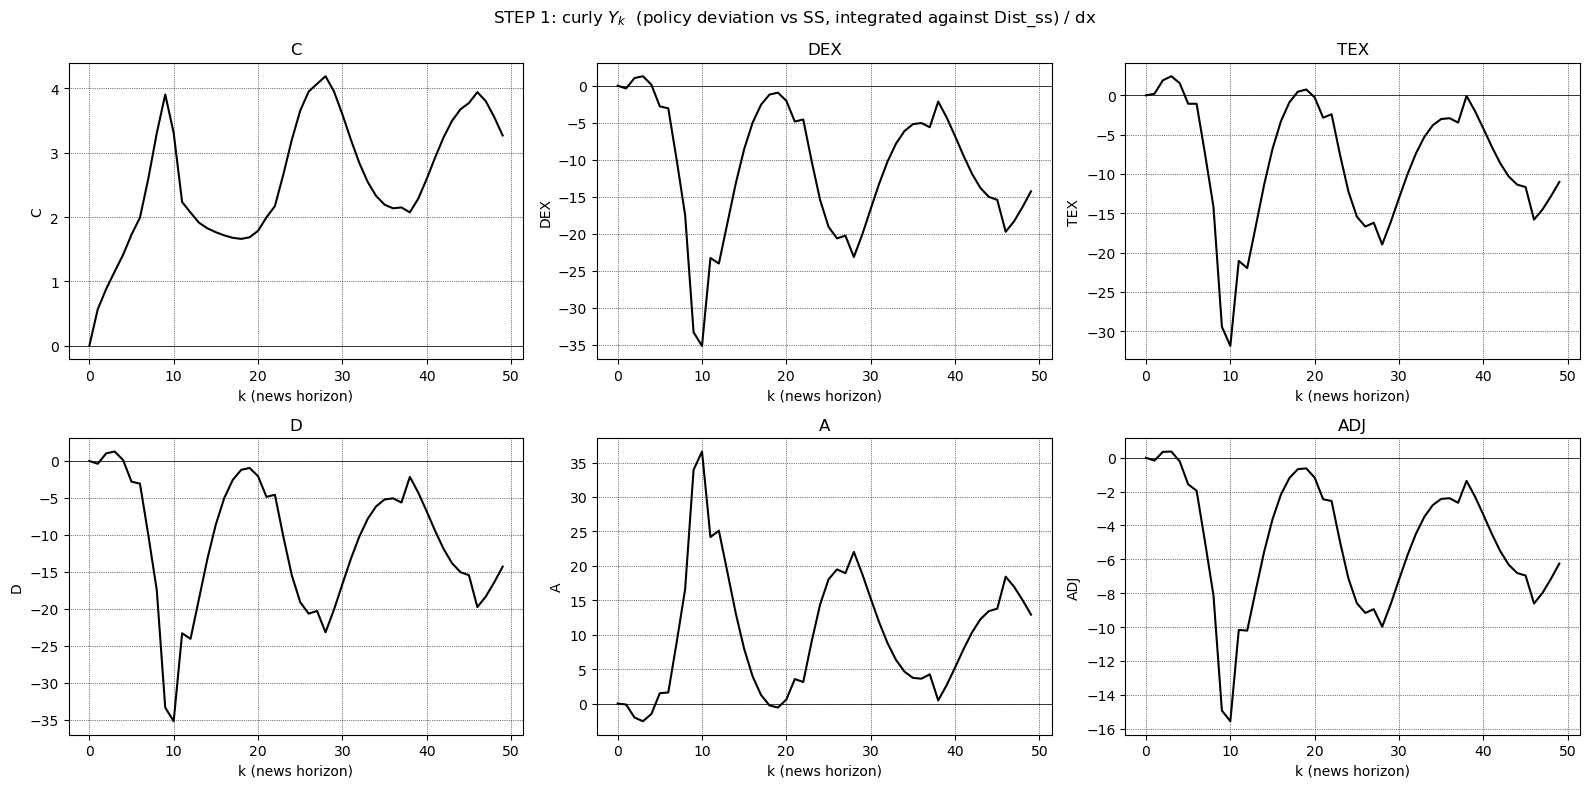

||Dist_curl_s[k]||_1:
  k= 0: 0.0000e+00
  k= 1: 6.4351e+00
  k= 2: 2.5459e+01
  k= 5: 9.5670e+01
  k=10: 4.2815e+02


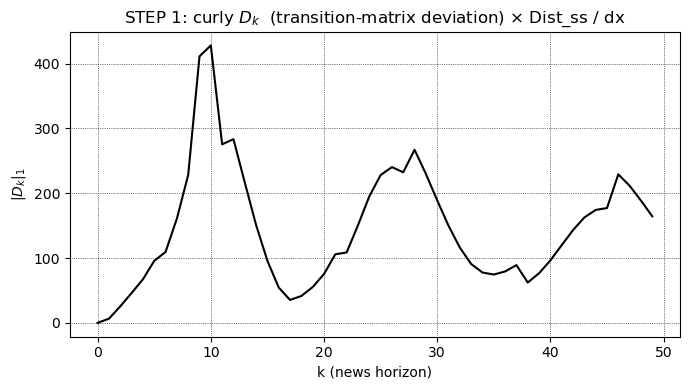

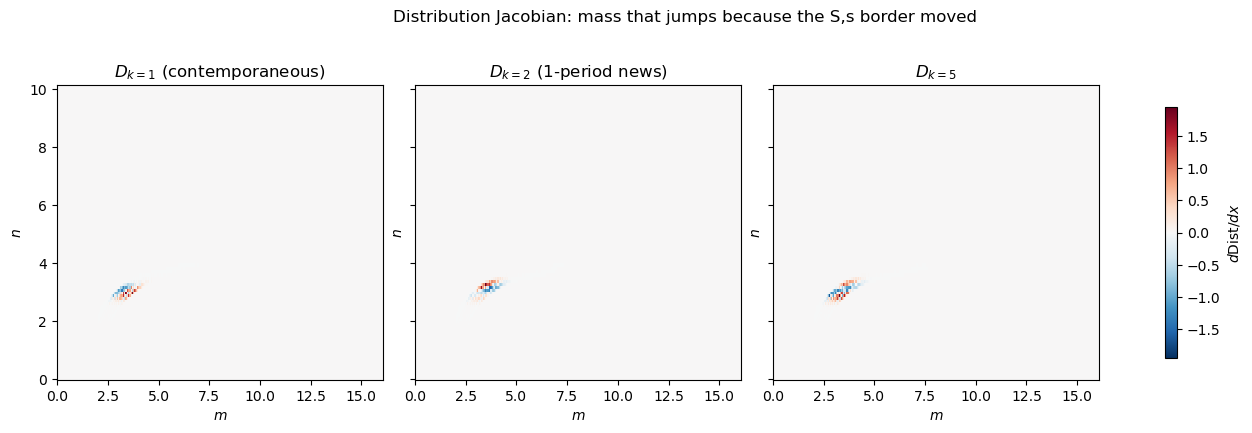

In [18]:
# STEP 1: policy deviations (curly Y) and distribution deviations (curly D).
A_curl_s = np.zeros(T)
C_curl_s = np.zeros(T)
D_curl_s = np.zeros(T)
DEX_curl_s = np.zeros(T)
ADJ_curl_s = np.zeros(T)
nStates = len(model.dist_nGrid) * len(model.dist_mGrid)
Dist_curl_s = np.zeros((T, nStates))
for k in range(T):
    A_curl_s[k] = ((a_t[T - k] - a_ss).flatten() @ Dist_ss) / dx
    C_curl_s[k] = ((c_t[T - k] - c_ss).flatten() @ Dist_ss) / dx
    D_curl_s[k] = ((d_t[T - k] - d_ss).flatten() @ Dist_ss) / dx
    DEX_curl_s[k] = ((dex_t[T - k] - dex_ss).flatten() @ Dist_ss) / dx
    ADJ_curl_s[k] = ((adj_t[T - k] - adj_ss).flatten() @ Dist_ss) / dx
    Dist_curl_s[k] = ((tranmat_t[T - k] - tranmat_ss) @ Dist_ss) / dx

TEX_curl_s = C_curl_s + DEX_curl_s
curl_Y = dict(C=C_curl_s, DEX=DEX_curl_s, TEX=TEX_curl_s, D=D_curl_s, A=A_curl_s, ADJ=ADJ_curl_s)
print("curly Y[k=0] (should be ~0, SS vs SS):", {k: float(v[0]) for k, v in curl_Y.items()})
print("curly Y[k=1] (contemporaneous):      ", {k: float(v[1]) for k, v in curl_Y.items()})

_plot_series(curl_Y, r"STEP 1: curly $Y_k$  (policy deviation vs SS, integrated against Dist_ss) / dx")

print("||Dist_curl_s[k]||_1:")
for k in [0, 1, 2, 5, 10]:
    if k < T:
        print(f"  k={k:2d}: {np.abs(Dist_curl_s[k]).sum():.4e}")

fig, ax = plt.subplots(figsize=(7.0, 4.0))
ax.plot(np.abs(Dist_curl_s).sum(axis=1), color="k")
ax.set_xlabel("k (news horizon)")
ax.set_ylabel(r"$\|D_k\|_1$")
ax.set_title(r"STEP 1: curly $D_k$  (transition-matrix deviation) $\times$ Dist_ss / dx")
ax.grid(color="k", linestyle=":", linewidth=0.5)
fig.tight_layout()
plt.show()

_heatmaps_row(
    [Dist_curl_s[1], Dist_curl_s[2], Dist_curl_s[min(5, T - 1)]],
    [r"$D_{k=1}$ (contemporaneous)", r"$D_{k=2}$ (1-period news)", r"$D_{k=5}$"],
    diverging=True,
    cbar=r"$d\mathrm{Dist}/dx$",
    suptitle="Distribution Jacobian: mass that jumps because the S,s border moved",
)


### STEP 2 — expectation vectors

SS policies propagated by the SS transition: $\mathcal{E}_{k+1} = \mathcal{E}_k P_{ss}$.
These are smooth. The spikes enter the fake-news matrix through $D_s$, not through $\mathcal{E}$.


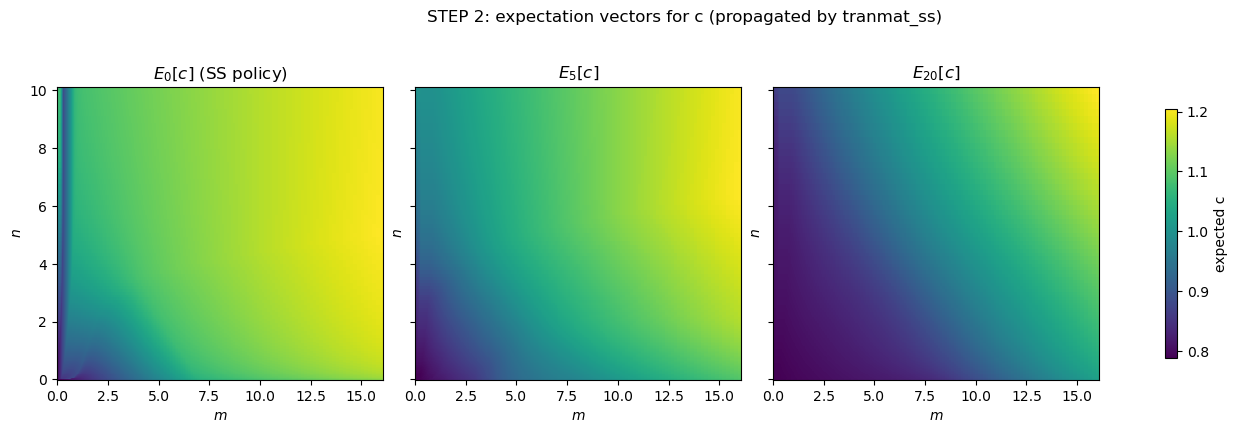

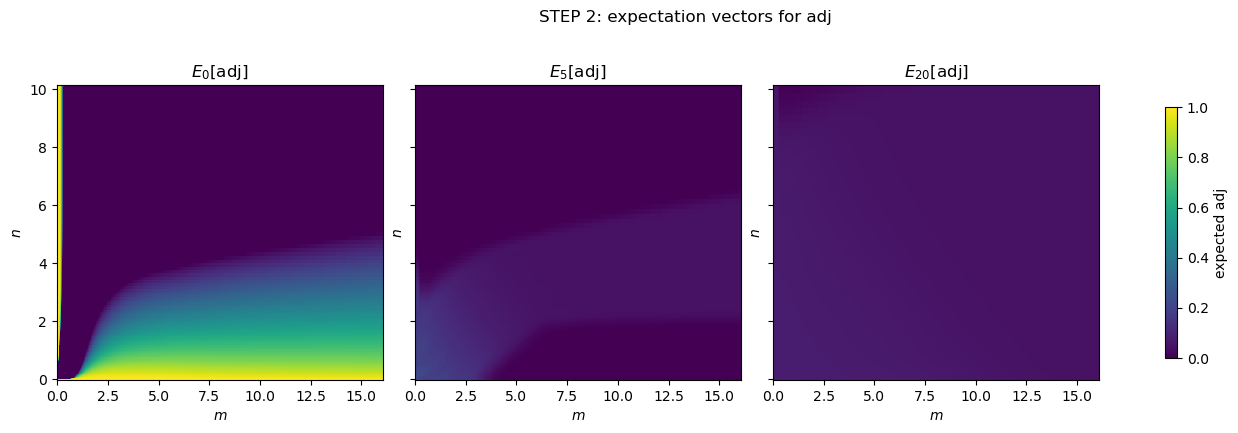

In [19]:
# STEP 2: expectation vectors propagated by the SS transition matrix.
exp_vecs_a = np.zeros((T, nStates))
exp_vecs_c = np.zeros((T, nStates))
exp_vecs_d = np.zeros((T, nStates))
exp_vecs_dex = np.zeros((T, nStates))
exp_vecs_adj = np.zeros((T, nStates))
ev_a = a_ss.flatten()
ev_c = c_ss.flatten()
ev_d = d_ss.flatten()
ev_dex = dex_ss.flatten()
ev_adj = adj_ss.flatten()
for k in range(T):
    exp_vecs_a[k] = ev_a
    exp_vecs_c[k] = ev_c
    exp_vecs_d[k] = ev_d
    exp_vecs_dex[k] = ev_dex
    exp_vecs_adj[k] = ev_adj
    ev_a = ev_a @ tranmat_ss
    ev_c = ev_c @ tranmat_ss
    ev_d = ev_d @ tranmat_ss
    ev_dex = ev_dex @ tranmat_ss
    ev_adj = ev_adj @ tranmat_ss

# k=0 is the SS policy itself; later k are discounted (here undiscounted) forecasts
# of that policy under the SS transition. Smooth forecasts vs a spiky Dist_curl
# still produce a spiky fake-news matrix.
_heatmaps_row(
    [exp_vecs_c[0], exp_vecs_c[min(5, T - 1)], exp_vecs_c[min(20, T - 1)]],
    [r"$E_0[c]$ (SS policy)", r"$E_5[c]$", r"$E_{20}[c]$"],
    diverging=False, cmap="viridis",
    cbar="expected c",
    suptitle="STEP 2: expectation vectors for c (propagated by tranmat_ss)",
)
_heatmaps_row(
    [exp_vecs_adj[0], exp_vecs_adj[min(5, T - 1)], exp_vecs_adj[min(20, T - 1)]],
    [r"$E_0[\mathrm{adj}]$", r"$E_5[\mathrm{adj}]$", r"$E_{20}[\mathrm{adj}]$"],
    diverging=False, vmin=0.0, vmax=1.0, cmap="viridis",
    cbar="expected adj",
    suptitle="STEP 2: expectation vectors for adj",
)


### STEP 3 — fake-news matrices

$\mathcal{F}_{0,s} = Y_s$ and $\mathcal{F}_{r+1,s} = \mathcal{E}_r \cdot D_s$.
A noisy $D_s$ makes every row of $\mathcal{F}_{\cdot,s}$ noisy.


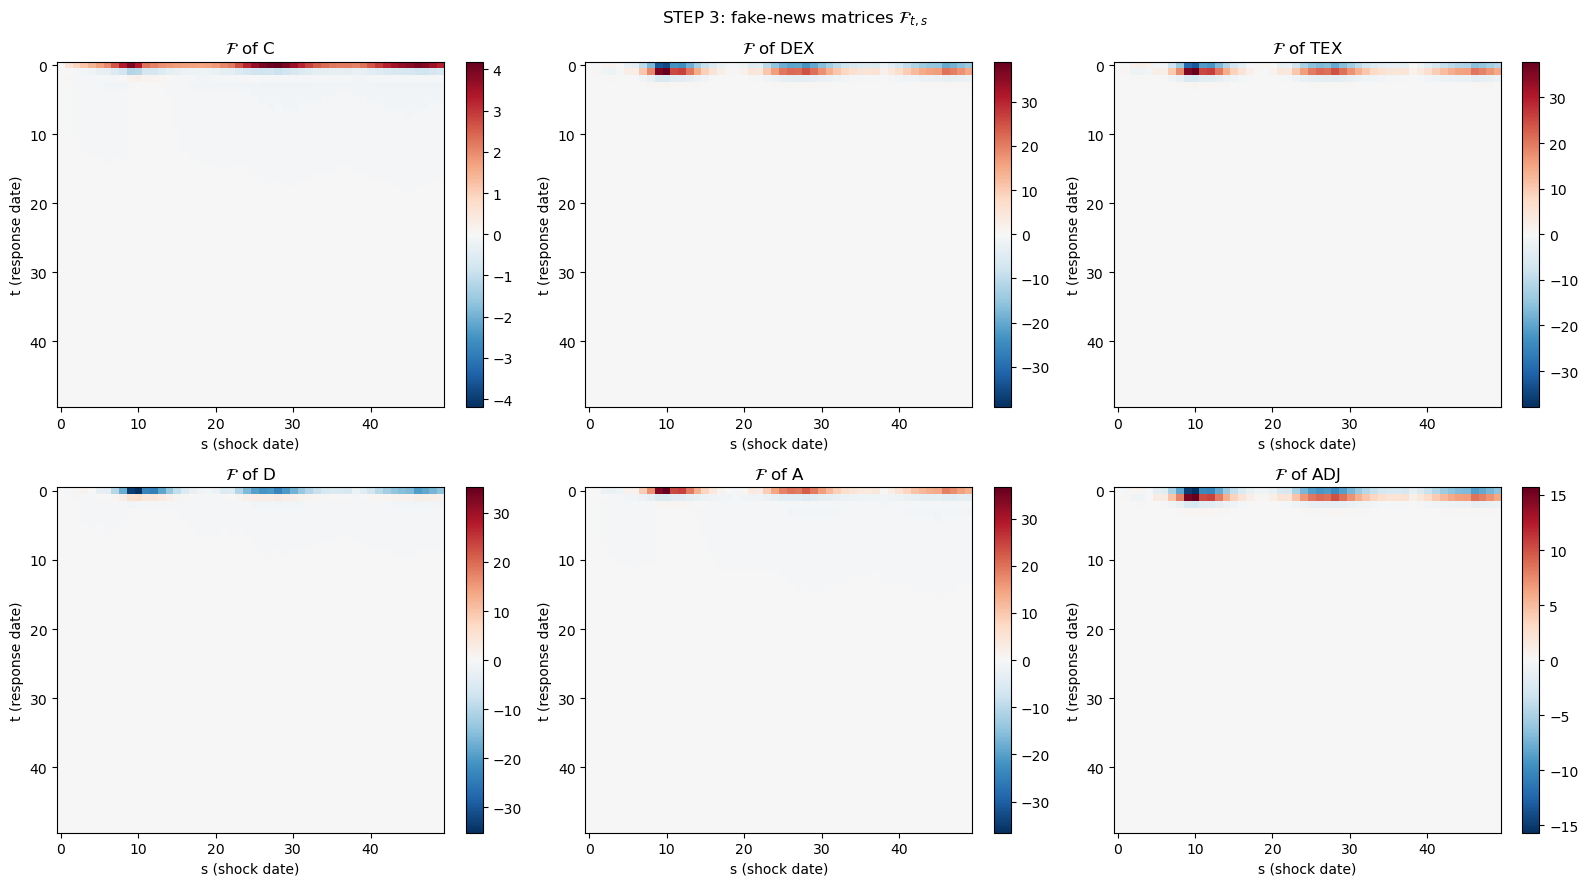

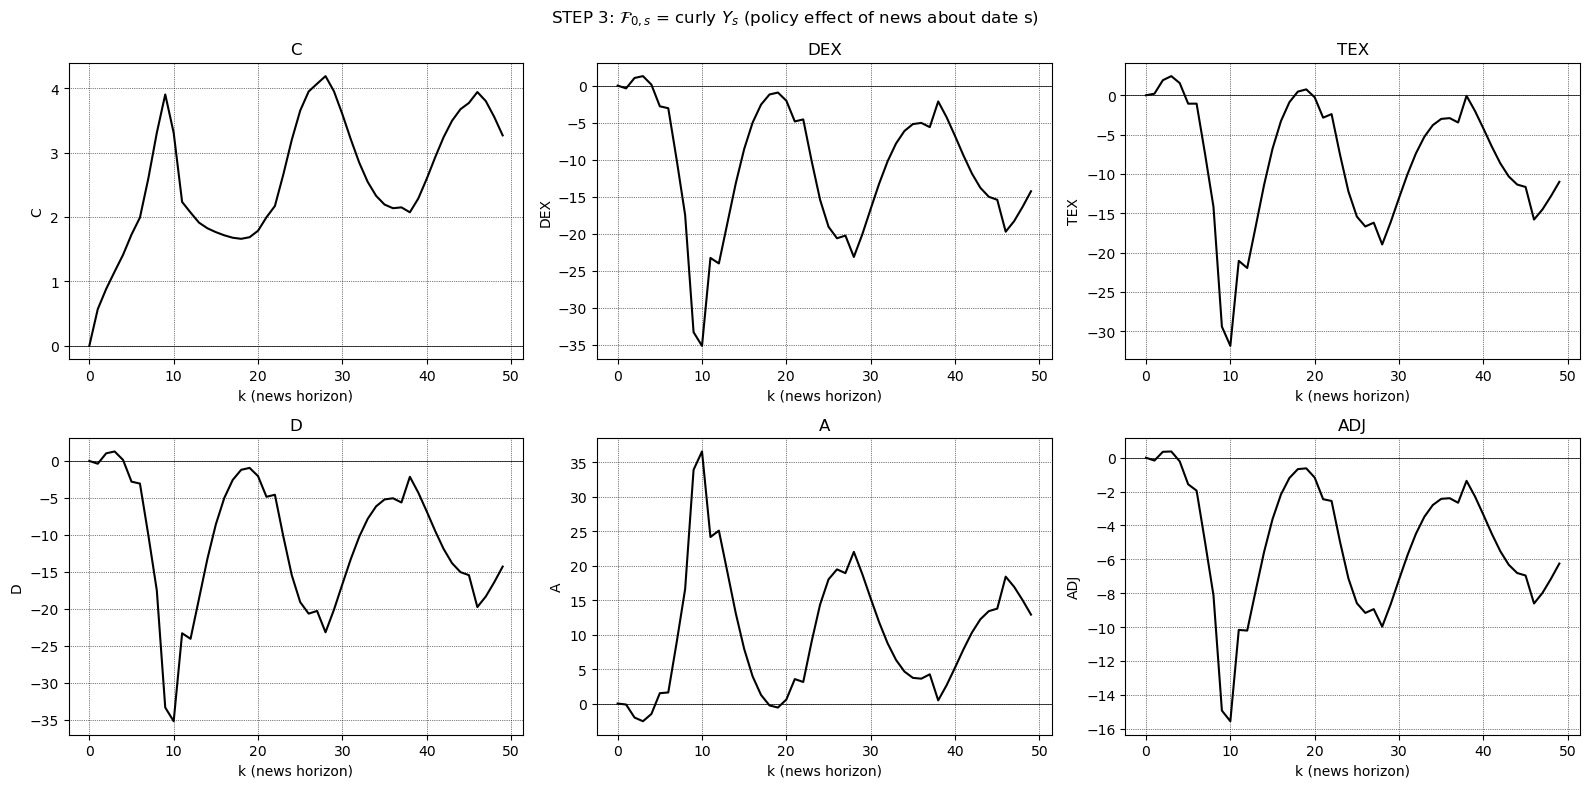

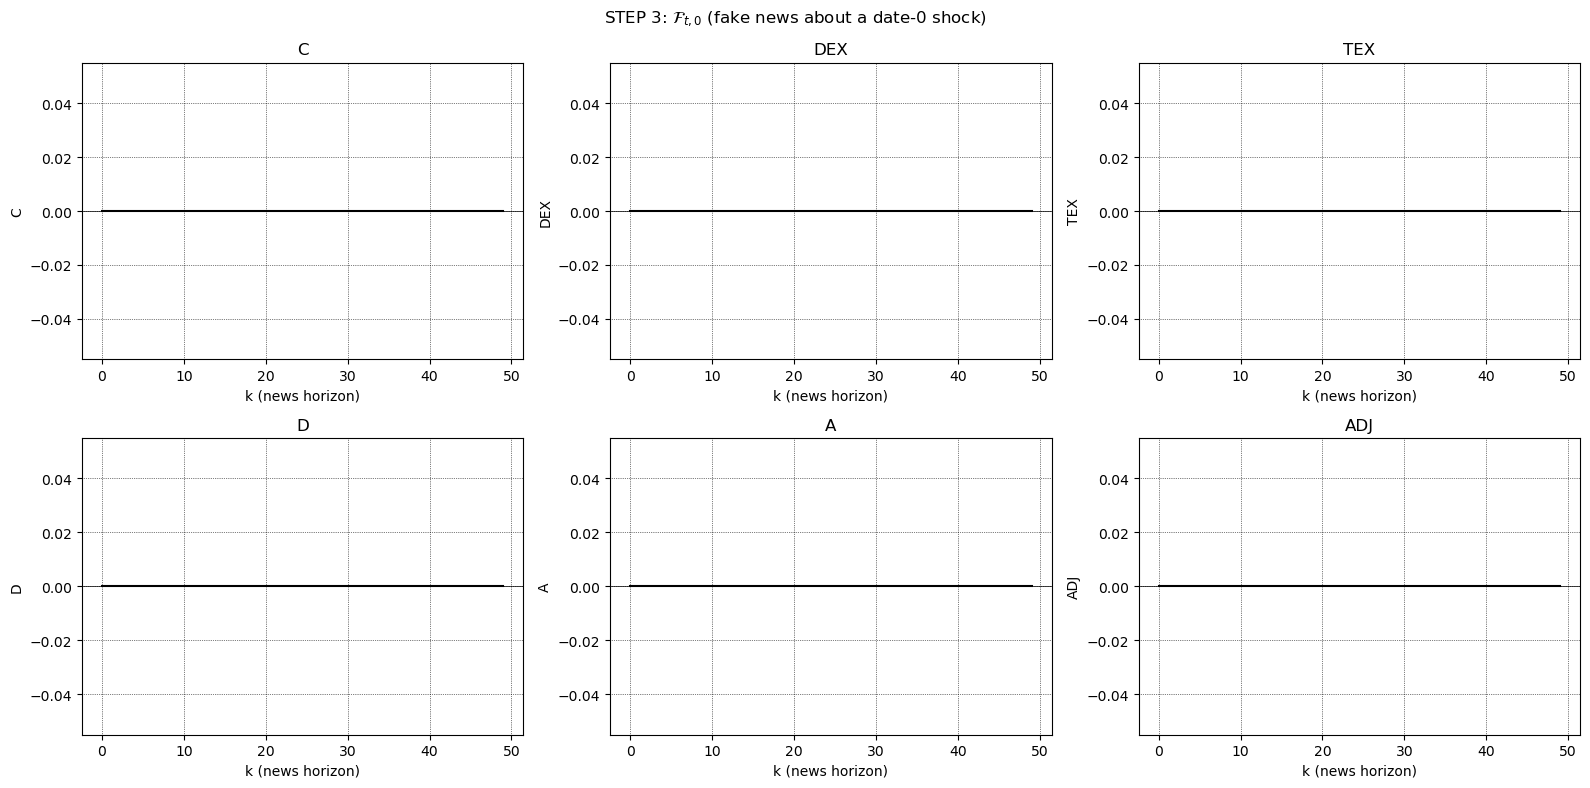

In [20]:
# STEP 3: fake-news matrices.
Curl_F_A = np.zeros((T, T))
Curl_F_C = np.zeros((T, T))
Curl_F_D = np.zeros((T, T))
Curl_F_DEX = np.zeros((T, T))
Curl_F_ADJ = np.zeros((T, T))
Curl_F_A[0] = A_curl_s
Curl_F_C[0] = C_curl_s
Curl_F_D[0] = D_curl_s
Curl_F_DEX[0] = DEX_curl_s
Curl_F_ADJ[0] = ADJ_curl_s
for r in range(T - 1):
    for s in range(T):
        Curl_F_A[r + 1][s] = np.dot(exp_vecs_a[r], Dist_curl_s[s])
        Curl_F_C[r + 1][s] = np.dot(exp_vecs_c[r], Dist_curl_s[s])
        Curl_F_D[r + 1][s] = np.dot(exp_vecs_d[r], Dist_curl_s[s])
        Curl_F_DEX[r + 1][s] = np.dot(exp_vecs_dex[r], Dist_curl_s[s])
        Curl_F_ADJ[r + 1][s] = np.dot(exp_vecs_adj[r], Dist_curl_s[s])

Curl_F_TEX = Curl_F_C + Curl_F_DEX
fake_news = dict(C=Curl_F_C, DEX=Curl_F_DEX, TEX=Curl_F_TEX, D=Curl_F_D, A=Curl_F_A, ADJ=Curl_F_ADJ)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, name in zip(axes.flat, JAC_KEYS):
    F = fake_news[name]
    lim = np.nanmax(np.abs(F))
    lim = 1.0 if (not np.isfinite(lim) or lim == 0.0) else lim
    im = ax.imshow(F, origin="upper", cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
    ax.set_title(rf"$\mathcal{{F}}$ of {name}")
    ax.set_xlabel("s (shock date)")
    ax.set_ylabel("t (response date)")
    fig.colorbar(im, ax=ax, fraction=0.046)
fig.suptitle(r"STEP 3: fake-news matrices $\mathcal{F}_{t,s}$")
fig.tight_layout()
plt.show()

# Row 0 of F is curly Y (policy effect). Column 0 is the unexpected-shock news path.
_plot_series(
    {k: fake_news[k][0] for k in JAC_KEYS},
    r"STEP 3: $\mathcal{F}_{0,s}$ = curly $Y_s$ (policy effect of news about date s)",
)
_plot_series(
    {k: fake_news[k][:, 0] for k in JAC_KEYS},
    r"STEP 3: $\mathcal{F}_{t,0}$ (fake news about a date-0 shock)",
)


### STEP 4 — $J$ from $\mathcal{F}$

`J_from_F` (Auclert et al. 2021, eq. 26): $J_{t,s} = \mathcal{F}_{t,s} + J_{t-1,s-1}$.
Spikes in $\mathcal{F}$ are copied down the diagonals of $J$. Column 0 is still
the fake-news path; the next cell replaces it with the MIT-shock simulation.


J[0,0] BEFORE overwriting the zeroth column (equals F[0,0] = curly Y[0] ~ 0):
  C   : 0.000000e+00
  DEX : 0.000000e+00
  TEX : 0.000000e+00
  D   : 0.000000e+00
  A   : 0.000000e+00
  ADJ : 0.000000e+00


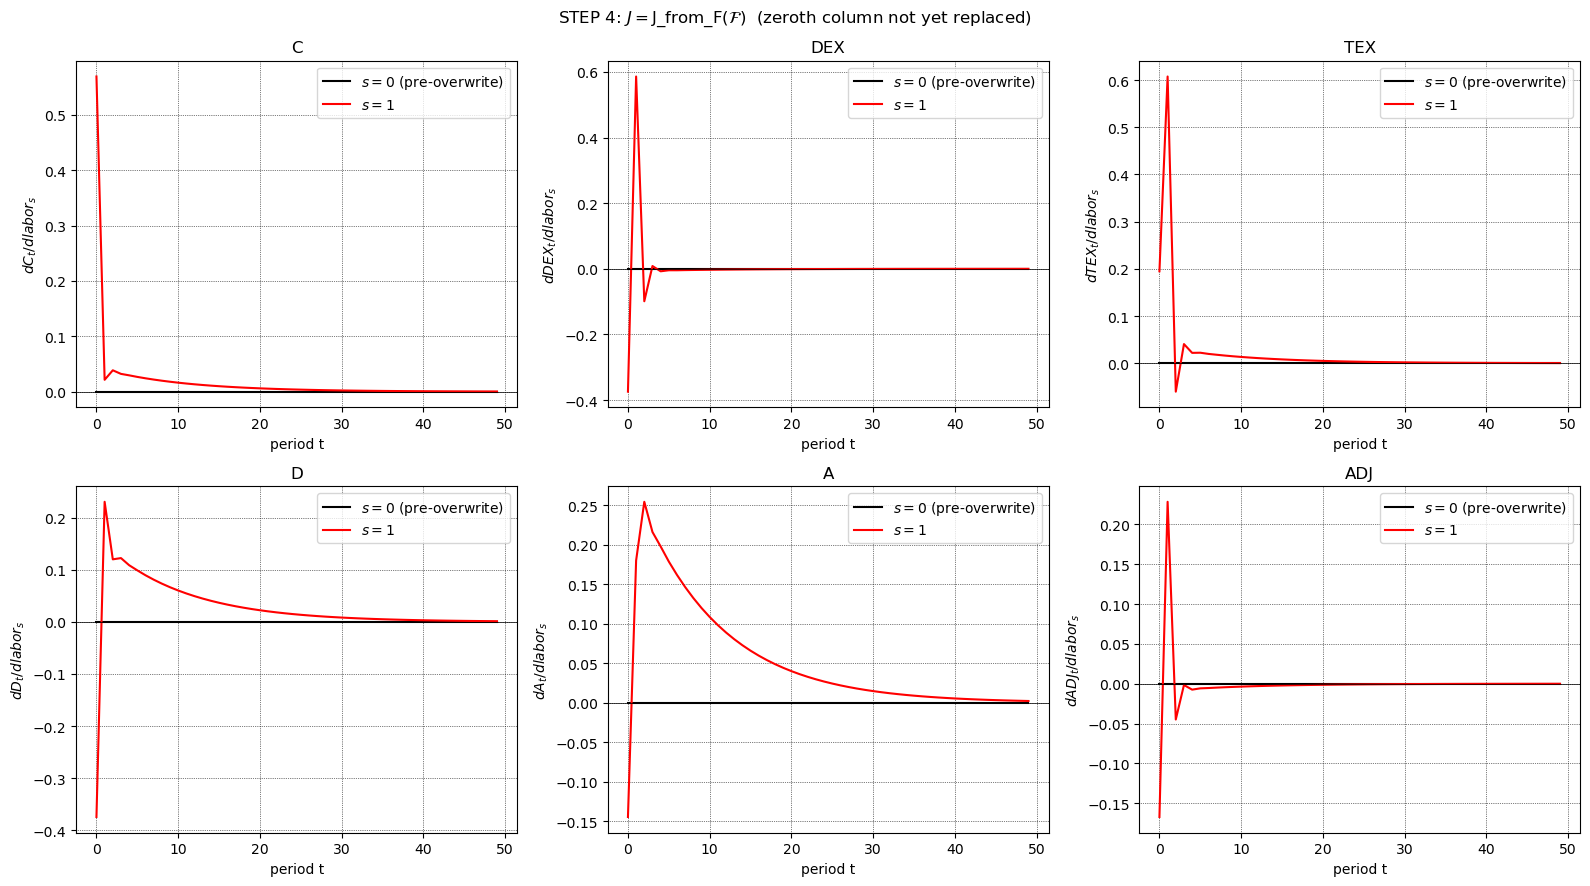

In [21]:
# STEP 4: Jacobians from fake-news matrices.
J_A = J_from_F(Curl_F_A)
J_C = J_from_F(Curl_F_C)
J_D = J_from_F(Curl_F_D)
J_DEX = J_from_F(Curl_F_DEX)
J_TEX = J_C + J_DEX
J_ADJ = J_from_F(Curl_F_ADJ)

J_before0 = dict(C=J_C.copy(), DEX=J_DEX.copy(), TEX=J_TEX.copy(), D=J_D.copy(), A=J_A.copy(), ADJ=J_ADJ.copy())
print("J[0,0] BEFORE overwriting the zeroth column (equals F[0,0] = curly Y[0] ~ 0):")
for name in JAC_KEYS:
    print(f"  {name:4s}: {J_before0[name][0, 0]:.6e}")

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, name in zip(axes.flat, JAC_KEYS):
    ax.plot(J_before0[name][:, 0], color="k", label=r"$s=0$ (pre-overwrite)")
    ax.plot(J_before0[name][:, 1], color="r", label=r"$s=1$")
    ax.axhline(0.0, color="k", lw=0.5)
    ax.set_title(name)
    ax.set_xlabel("period t")
    ax.set_ylabel(rf"$d{name}_t / d{shk_param}_s$")
    ax.grid(color="k", linestyle=":", linewidth=0.5)
    ax.legend(loc="best")
fig.suptitle(r"STEP 4: $J=\mathrm{J\_from\_F}(\mathcal{F})$  (zeroth column not yet replaced)")
fig.tight_layout()
plt.show()


### Zeroth column (MIT shock at date 0)

A 2-period agent is shocked in period 0. Only its transition matrix is used:
the SS policy is applied to the moved distribution. This overwrites $J_{\cdot,0}$,
including the impact element $J[0,0]$.


In [22]:
# -- Zeroth column via a 2-period agent shocked at period 0 -------------
ZerothColAgent = model._make_finite_agent(2)
path0 = [ss_val + dx, ss_val]
ZerothColAgent._solve_perturbed_finite({shk_param: path0})
ZerothColAgent.define_distribution_grid_dur()
ZerothColAgent.calc_transition_matrix_dur_cond(param_path={shk_param: path0})
tranmat_zeroth = ZerothColAgent.tran_matrix[0]

dstn = model.vec_erg_dstn.T
A_t_no_sim = np.zeros(T)
C_t_no_sim = np.zeros(T)
D_t_no_sim = np.zeros(T)
DEX_t_no_sim = np.zeros(T)
ADJ_t_no_sim = np.zeros(T)
for k in range(T):
    dstn = (tranmat_zeroth if k == 0 else tranmat_ss) @ dstn
    A_t_no_sim[k] = model.aPol_Grid.flatten() @ dstn
    C_t_no_sim[k] = model.cPol_Grid.flatten() @ dstn
    D_t_no_sim[k] = model.dPol_Grid.flatten() @ dstn
    DEX_t_no_sim[k] = model.dexPol_Grid.flatten() @ dstn
    ADJ_t_no_sim[k] = model.adjPol_Grid.flatten() @ dstn

J_A.T[0] = (A_t_no_sim - model.A_ss) / dx
J_C.T[0] = (C_t_no_sim - model.C_ss) / dx
J_D.T[0] = (D_t_no_sim - model.D_ss) / dx
J_DEX.T[0] = (DEX_t_no_sim - model.DEX_ss) / dx
J_TEX.T[0] = J_C.T[0] + J_DEX.T[0]
J_ADJ.T[0] = (ADJ_t_no_sim - model.ADJ_ss) / dx


Zeroth-column agent, period 0 vs SS (the border shift that feeds J[:,0]):
ADJ : max|d/dx|=3.9343e+01  mean|d/dx|=6.0889e-01  p99|d/dx|=1.1607e+01
D   : max|d/dx|=2.5806e+01  mean|d/dx|=1.7950e+00  p99|d/dx|=1.5853e+01
C   : max|d/dx|=8.1056e+00  mean|d/dx|=6.3743e-01  p99|d/dx|=6.5052e+00


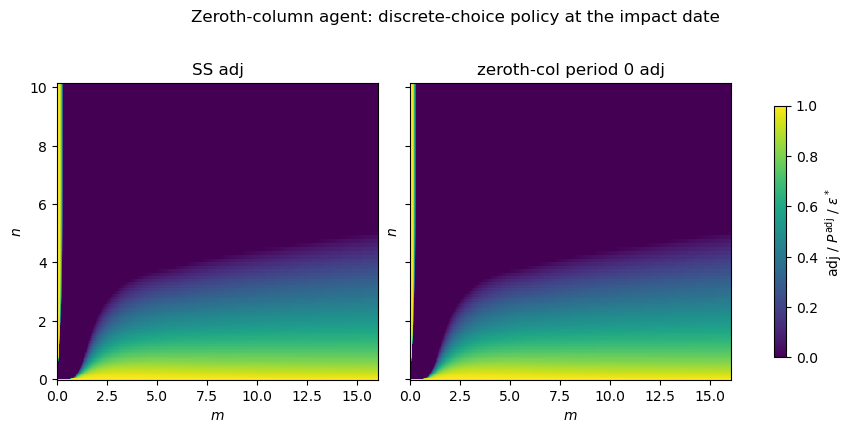

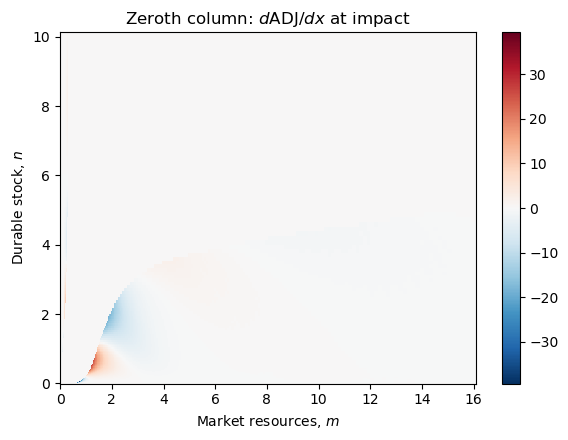

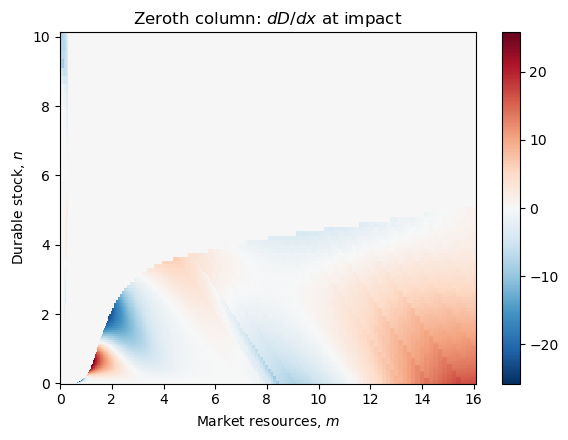

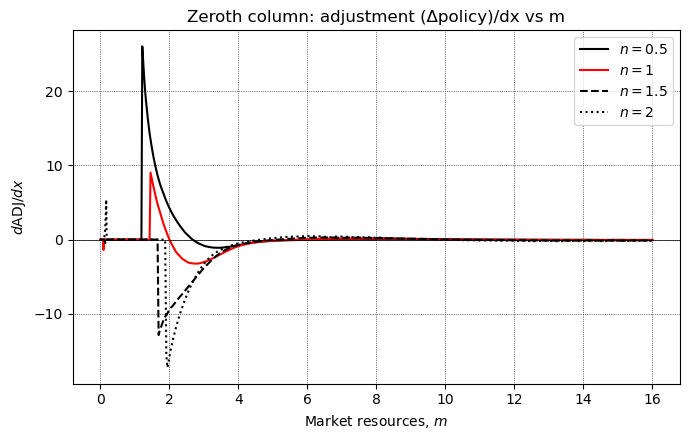

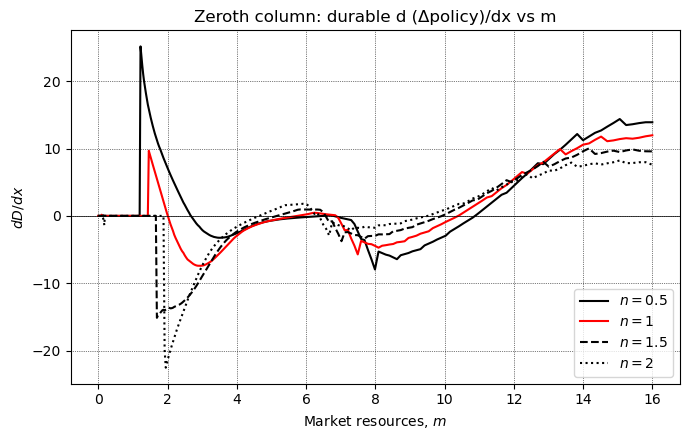

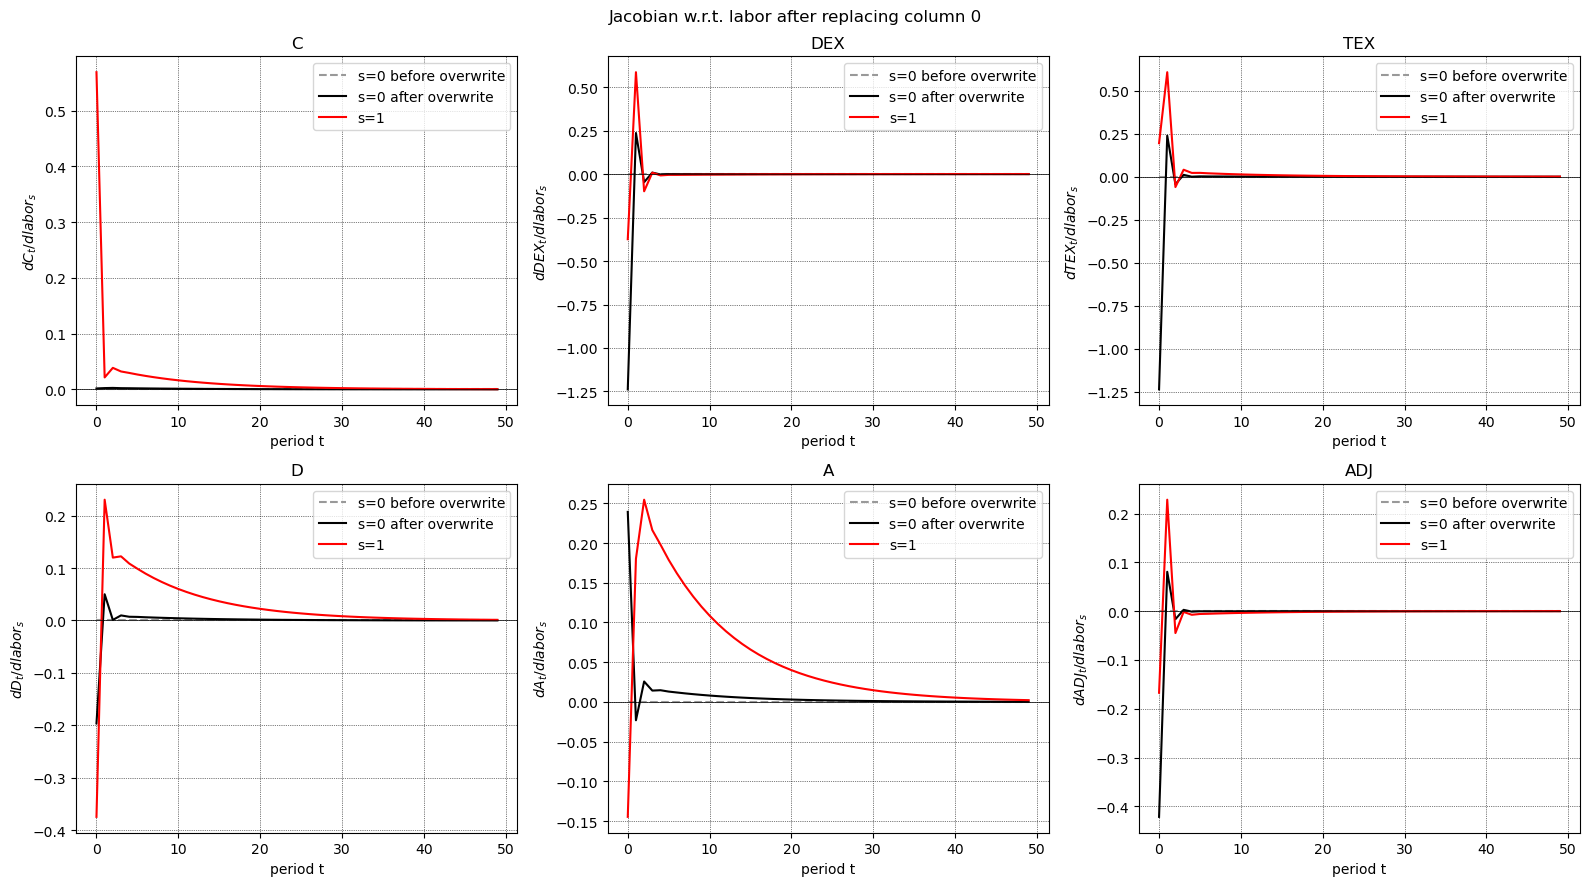

J[0,0] AFTER zeroth-column overwrite (this is the impact response):


,C,DEX,TEX,D,A,ADJ
"J[0,0]",0.001647,-1.237875,-1.236229,-0.196106,0.239186,-0.421639


In [23]:
# Period-0 policies of the 2-period agent: these enter J[:,0] only through
# tranmat_zeroth (SS policies are then applied to the moved distribution).
adj_z0 = ZerothColAgent.adjPol_Grid[0]
c_z0 = ZerothColAgent.cPol_Grid[0]
d_z0 = ZerothColAgent.dPol_Grid[0]

print("Zeroth-column agent, period 0 vs SS (the border shift that feeds J[:,0]):")
_jump_stats(adj_ss, adj_z0, "ADJ")
_jump_stats(d_ss, d_z0, "D")
_jump_stats(c_ss, c_z0, "C")

_heatmaps_row(
    [adj_ss, adj_z0],
    ["SS adj", "zeroth-col period 0 adj"],
    diverging=False, vmin=0.0, vmax=1.0, cmap="viridis",
    cbar=r"adj / $P^{\mathrm{adj}}$ / $\varepsilon^*$",
    suptitle="Zeroth-column agent: discrete-choice policy at the impact date",
)
_heatmap((np.asarray(adj_z0) - np.asarray(adj_ss)) / dx, r"Zeroth column: $d\mathrm{ADJ}/dx$ at impact")
_heatmap((np.asarray(d_z0) - np.asarray(d_ss)) / dx, r"Zeroth column: $dD/dx$ at impact")
_slices_d_dx(adj_ss, adj_z0, r"$d\mathrm{ADJ}/dx$", "Zeroth column: adjustment (Δpolicy)/dx vs m")
_slices_d_dx(d_ss, d_z0, r"$dD/dx$", "Zeroth column: durable d (Δpolicy)/dx vs m")

J = dict(C=J_C, DEX=J_DEX, TEX=J_TEX, D=J_D, A=J_A, ADJ=J_ADJ)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, name in zip(axes.flat, JAC_KEYS):
    ax.plot(J_before0[name][:, 0], color="0.6", linestyle="--", label="s=0 before overwrite")
    ax.plot(J[name][:, 0], color="k", label="s=0 after overwrite")
    ax.plot(J[name][:, 1], color="r", label="s=1")
    ax.axhline(0.0, color="k", lw=0.5)
    ax.set_title(name)
    ax.set_xlabel("period t")
    ax.set_ylabel(rf"$d{name}_t / d{shk_param}_s$")
    ax.grid(color="k", linestyle=":", linewidth=0.5)
    ax.legend(loc="best")
fig.suptitle(rf"Jacobian w.r.t. {shk_param} after replacing column 0")
fig.tight_layout()
plt.show()

j00 = {k: float(J[k][0, 0]) for k in JAC_KEYS}
print("J[0,0] AFTER zeroth-column overwrite (this is the impact response):")
display(pd.DataFrame(j00, index=["J[0,0]"]).style.format("{:.6f}"))
